# Полный расчёт ТВД мощностью 150 л.с. при $\pi_k^*=6$

В одном ноутбуке последовательно выполнены:

1. термогазодинамический расчёт цикла двигателя;
2. выбор расчётной точки $\pi_k^*=6$;
3. проектирование одноступенчатой турбины компрессора;
4. проектирование одноступенчатой свободной силовой турбины;
5. совместный подбор геометрии, проверка ограничений, треугольники скоростей и меридиональное сечение.

Все величины в коде приведены к единицам, указанным рядом с формулами и в таблицах. В расчёте цикла работы и теплоёмкости заданы в кДж/кг и кДж/(кг·К); внутри расчёта ступеней они переводятся в Дж/кг и Дж/(кг·К).

# Расчёт цикла двигателя

### Прототипы:
- tj100
- ТВД150 МКБ «Гранит»
- Honeywell TPE331

## 1. Импорт библиотек, исходные данные

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#-------------------------------------------
pd.set_option('display.max_rows', None)      #чтобы было видно все строки в pandas
pd.set_option('display.max_columns', None)
# Десятичный вывод с 4 знаками после точки; точность вычислений сохраняется.
pd.set_option('display.float_format', '{:.4f}'.format)
#-------------------------------------------

# Мощность двигателя
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
n_variants = 801

KCAL_TO_KJ = 4.187

print(f"Мощность на валу: {power_hp:.0f} л.с. = {power_kw:.3f} кВт")

Мощность на валу: 150 л.с. = 110.325 кВт


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

**Формулы следующей ячейки: теплофизические свойства и деление пополам**

Обозначения: $T$ — К, $\alpha$ — коэффициент избытка воздуха, $a=1/\alpha$; для воздуха $a=0$. Теплоёмкости — **кДж/(кг·К)**. В коде `cp_i` — истинная, `cp_m` — средняя теплоёмкость.

Вспомогательные полиномы температуры:

$$U=2.5\cdot10^{-3}T-0.875,\qquad V=2.5\cdot10^{-5}T^2-0.0275T+6.5625,$$
$$W=1.176\cdot10^{-3}T-0.88235,\qquad Z=5.5556\cdot10^{-6}T^2-0.013056T+6.67.$$

$$c_{pi}(T,\alpha)=4.187\begin{cases}
0.0174a+0.2407+(0.0093a+0.0193)U+\left(0.002-\dfrac{0.001056a}{1-0.2a}\right)V,&T<750,\\[2mm]
0.0267a+0.26+(0.0133a+0.032)W-\left(0.00374+\dfrac{0.0094a^2}{1+10a^2}\right)Z,&T\ge750.
\end{cases}$$

$$
c_{pm}(T,\alpha)=4.187\begin{cases}
\dfrac{2.25a+1.2}{10^5}(T-70)+0.236,&T<700,\\
\dfrac{1.25a+2.2}{10^5}(T+450)+0.218,&T\ge700.
\end{cases}
$$

Функции энтальпии записаны **точно как в существующем коде**:

$$h(T,\alpha)=c_{pm}(T,\alpha)T,\qquad
\Delta h(T,\alpha)=h(T,\alpha)-h(T_{ref},\alpha).$$

`process_properties` использует приближение:

$$T_m=\frac{T_1+T_2}{2},\qquad c_p=c_{pi}(T_m,\alpha),\qquad k=\frac{c_p}{c_p-R}.$$

В `bisect` решается $F(x)=0$: $m=(l+r)/2$; если $F(l)F(m)\le0$, заменяем $r=m$, иначе $l=m$. После 80 шагов возвращается $(l+r)/2$. Это выбранный численный алгоритм, не отдельная физическая формула.

**Источник:** «цикл.pdf», приложение 6, с. 56–57; согласование свойств процесса — §2.3, с. 16. Определения `h`, `dh` и правила осреднения показаны здесь для объяснения уже имеющегося кода, без изменения его модели.


In [2]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

**Формулы следующей функции `inlet()`**

$T_a,p_a,V$ — статические параметры атмосферы и скорость полёта. Индекс 2 — вход компрессора; возвращаемые $T_2,p_2$ — **полные** параметры.

$$c_p=c_{pi}\left(\frac{T_a+T_2}{2},\infty\right),\qquad k=\frac{c_p}{c_p-R_a},$$
$$c_p(T_2-T_a)=\frac{V^2}{2000},\qquad
M=\frac{V}{\sqrt{1000kR_aT_a}},$$
$$\pi_V=\left(\frac{T_2}{T_a}\right)^{k/(k-1)},\qquad
p_2=p_a\pi_V\sigma_{in}.$$

$T_2$ находится делением пополам. Числа 1000 и 2000 связаны с использованием кДж. При $V=0$: $T_2=T_a$, $\pi_V=1$.

**Источник:** «цикл.pdf», §2.1, с. 10 — полные параметры на входе и коэффициент сохранения давления. Выражения через $V$ — раскрытие перехода от статических к полным параметрам, уже реализованное в исходном ноутбуке.


In [3]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

**Формулы следующей функции `compressor()`**

$\pi_k=p_3/p_2$ — степень повышения полного давления; $\eta_{kp}$ — политропический КПД. Свойства определяются по средней температуре $T_m=(T_2+T_3)/2$.

$$c_p=c_{pi}(T_m,\infty),\quad k=\frac{c_p}{c_p-R_a},\quad
T_3=T_2\pi_k^{(k-1)/(k\eta_{kp})},$$
$$\eta_k=\frac{\pi_k^{(k-1)/k}-1}{\pi_k^{(k-1)/(k\eta_{kp})}-1},\qquad
p_3=p_2\pi_k,\qquad L_k=c_p(T_3-T_2).$$

$T_3$ решается неявно, поскольку $c_p$ и $k$ зависят от неё. В коде `expm1(x)` означает $e^x-1$ и сохраняет точность при малом $x$.

**Источник:** «цикл.pdf», с. 9 — переход от политропического КПД к адиабатному; §2.2, с. 11–12 — параметры и работа компрессора. Формула $T_3$ — преобразование этих соотношений.


In [4]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

**Формулы следующей функции `combustor()`**

`gm` — расход топлива, отнесённый к воздуху, поступающему в камеру сгорания. $h$ и $\Delta h$ — функции предыдущего раздела. В числителе существующего кода используется $h(T,\infty)$:

$$D_Q=Q_H\eta_b-(1+l_0)\Delta h(T_g,1)+l_0\Delta h(T_g,\infty),$$
$$g_m=\frac{h(T_g,\infty)-h(T_3,\infty)}{D_Q},\qquad
\alpha=\frac{1}{g_ml_0}.$$

Доли расходов относительно воздуха через компрессор:

$$b=1-g_{ут}-g_{охл},\qquad
f=bg_m,\qquad g_g=b(1+g_m),\qquad p_g=p_3\sigma_b.$$

Соответствие коду: `fuel_air` $=f$, `gas_air` $=g_g$, `pg` $=p_g$.

**Источник:** «цикл.pdf», §3.1, с. 19–21 — уточнённый расход топлива и состав продуктов сгорания; §3.2, с. 22 — относительные расходы. Формулы записаны в форме реализованной функции, без изменения исходного расчёта.


In [5]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

**Формулы следующих функций `turbine_eta()` и `gas_generator_turbine()`**

Для произвольной турбины при $\pi_t=p_{in}^*/p_{out}^*$ и политропическом КПД $\eta_{tp}$:

$$\eta_t^*=\frac{1-\pi_t^{-(k-1)\eta_{tp}/k}}{1-\pi_t^{-(k-1)/k}}.$$

Для турбины компрессора (ТК, газогенератора):

$$L_{ГГ}=\frac{L_k}{g_g\eta_{m,ГГ}},\qquad
c_p=c_{pi}\left(\frac{T_g+T_4}{2},\alpha\right),\qquad k=\frac{c_p}{c_p-R_g},$$
$$c_p(T_g-T_4)=L_{ГГ},\qquad
\pi_{ГГ}=\left(\frac{T_g}{T_4}\right)^{k/[(k-1)\eta_{p,ГГ}]},\qquad
p_4=\frac{p_g}{\pi_{ГГ}}.$$

Температуры и давления здесь полные. $T_4$ находится из баланса работы; затем рассчитывается адиабатный КПД функцией `turbine_eta`.

**Источник:** «цикл.pdf», с. 9 — пересчёт КПД; с. 17–19 — баланс мощностей и параметры компрессорной турбины. Формула $\pi_{ГГ}$ — преобразование политропического соотношения.


In [6]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

**Формулы следующих функций `static_from_total()` и `power_turbine()`**

Переход от полных параметров к статическим при скорости $c$:

$$c_p=c_{pi}\left(\frac{T^*+T}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g},\quad
c_p(T^*-T)=\frac{c^2}{2000},$$
$$M=\frac{c}{\sqrt{1000kR_gT}},\qquad r=\frac{p^*}{p}=\left(\frac{T^*}{T}\right)^{k/(k-1)}.$$

Для силовой турбины в модели цикла задаются статическое давление и выходная скорость:

$$p_5=\pi_{с,стат}\,p_a,\qquad c_5=c_{pt,exit},\qquad p_5^*=p_5r_5.$$

Неизвестная $T_5^*$ определяется совместно с переходом к статическим параметрам:

$$T_5^*=T_4\left(\frac{p_5^*}{p_4}\right)^{(k-1)\eta_{p,СТ}/k},\qquad
c_p=c_{pi}\left(\frac{T_4+T_5^*}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g}.$$

После решения:

$$\pi_{СТ}=\frac{p_4}{p_5^*},\quad L_{СТ}=c_p(T_4-T_5^*),\quad
\pi_{с}=\frac{p_5^*}{p_a},\quad
\eta_{СТ}^*=\frac{1-\pi_{СТ}^{-(k-1)\eta_{p,СТ}/k}}{1-\pi_{СТ}^{-(k-1)/k}}.$$

**Источник:** «цикл.pdf», с. 9 и §2.3, с. 16–19. Полное давление $p_5^*$ и статическое $p_5$ — разные величины; связь раскрыта по энергетическому и изоэнтропическому соотношениям, используемым исходным кодом. Значения $\pi_{с,стат}$ и $c_5$ — входные решения проекта.


In [7]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

**Формулы следующей функции `nozzle()`**

Для существующей модели полного расширения до $p_a$:

$$\pi_с=\frac{p_5^*}{p_a},\qquad
H_с=c_pT_5^*\left(1-\pi_с^{-(k-1)/k}\right),$$
$$T_с=T_5^*-\frac{\varphi_с^2H_с}{c_p},\qquad
c_с=\varphi_с\sqrt{2000H_с},\qquad p_с=p_a.$$

Свойства уточняются по $(T_5^*+T_с)/2$. Удельная тяга сопла, отнесённая к расходу воздуха:

$$R_{уд}=g_g(c_с-V).$$

**Источник:** «цикл.pdf», §3.2, с. 24–27 — реактивное сопло и удельная тяга. Это описание действующей функции: она предполагает полное расширение и не содержит отдельной ветви запертого сопла и члена $(p_с-p_a)A_с$. Код в рамках добавления формул не изменяется.


In [8]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

**Формулы следующей функции `performance()`**

Работы — кДж/кг, мощности — кВт; $G$ — кг/с.

$$N_{уд}=g_gL_{СТ}\eta_{m,СТ}\eta_r,\qquad
G_в=\frac{N_e}{N_{уд}},\qquad G_{в,г}=bG_в,$$
$$G_f=g_mG_{в,г},\qquad G_g=g_gG_в,\qquad G_{f,ч}=3600G_f,\qquad R_с=G_вR_{уд}.$$

Добавка эквивалентной мощности в существующем коде:

$$\Delta N_{уд}=\begin{cases}
R_{уд}/\beta_{винт},&V=0,\\
R_{уд}V/(1000\eta_{винт}),&V\ne0,
\end{cases}$$
$$N_{экв,уд}=N_{уд}+\Delta N_{уд},\qquad N_{экв}=G_вN_{экв,уд}.$$

$$C_{e,вал}=\frac{3600G_f}{N_e},\qquad
C_{e,экв}=\frac{3600G_f}{N_{экв}},\qquad
C_{e,лс}=0.73549875\,C_{e,вал},$$
$$\eta_{вал}=\frac{3600}{C_{e,вал}Q_H},\qquad
\eta_{экв}=\frac{3600}{C_{e,экв}Q_H}.$$

Здесь $C_e$ — кг/(кВт·ч), $Q_H$ — кДж/кг. Мощности агрегатов до механических потерь:

$$N_k=G_вL_k,\qquad N_{ГГ}=G_gL_{ГГ},\qquad N_{СТ}=G_gL_{СТ}.$$

**Источник:** «цикл.pdf», §3.2, с. 22–26 — удельные мощности и эквивалентная мощность ТВД; §3.3, с. 42–44 — экономичность; §4, с. 45 — расходы. Пересчёты на вал, редуктор и единицы — раскрытие используемых балансов. Значения $\beta_{винт}$ и $\eta_{винт}$ заданы в исходном ноутбуке, здесь они не объявляются результатом расчёта винта.


In [9]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

**Порядок следующей функции `cycle(pi_k)`**


$$\pi_k\longrightarrow\text{вход}\longrightarrow\text{компрессор}\longrightarrow
\text{камера сгорания}\longrightarrow\text{ТК}\longrightarrow\text{СТ}\longrightarrow
\text{сопло}\longrightarrow\text{мощность и расходы}.$$


In [10]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Вариантный расчёт и выбор pi_k

Сначала считаем диапазон значений pi_k, затем ищем минимум расхода воздуха и минимум удельного расхода топлива.

In [11]:
T2 = inlet()['T2']
upsilon = T_g / T2
pi_low = upsilon
pi_high = upsilon**2.4

pi_grid = np.linspace(pi_low, pi_high, n_variants)
records = []

for pi_k in pi_grid:
    records.append(cycle(pi_k))

variants = pd.DataFrame(records)

idx_L = variants['G_air'].idxmin()
idx_eta = variants['Ce_shaft'].idxmin()

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

# После вариантного расчёта выбираем единую точку для всех результатов
pi_k_selected = 6.0
selected_pi = pi_k_selected

s = cycle(selected_pi)

print(f"Диапазон πк*: {pi_low:.3f} ... {pi_high:.3f}")
print(f"Минимум расхода воздуха: πк* = {opt_L['pi_k']:.3f}")
print(f"Минимум удельного расхода топлива: πк* = {opt_eta['pi_k']:.3f}")
print(f"Принятое значение: πк* = {selected_pi:.3f}")

Диапазон πк*: 4.340 ... 33.888
Минимум расхода воздуха: πк* = 9.400
Минимум удельного расхода топлива: πк* = 18.819
Принятое значение: πк* = 6.000


## 12. Основные результаты

In [12]:
comparison = pd.DataFrame([
    {
        'Вариант': 'Минимум расхода воздуха',
        'πк*': opt_L['pi_k'],
        'Gв, кг/с': opt_L['G_air'],
        'Ce, кг/(кВт·ч)': opt_L['Ce_shaft'],
        'Gтопл, кг/ч': opt_L['fuel_hour'],
        'ηe, %': 100*opt_L['eta_shaft']
    },
    {
        'Вариант': 'Минимум Ce',
        'πк*': opt_eta['pi_k'],
        'Gв, кг/с': opt_eta['G_air'],
        'Ce, кг/(кВт·ч)': opt_eta['Ce_shaft'],
        'Gтопл, кг/ч': opt_eta['fuel_hour'],
        'ηe, %': 100*opt_eta['eta_shaft']
    },
    {
        'Вариант': 'Выбранный',
        'πк*': s['pi_k'],
        'Gв, кг/с': s['G_air'],
        'Ce, кг/(кВт·ч)': s['Ce_shaft'],
        'Gтопл, кг/ч': s['fuel_hour'],
        'ηe, %': 100*s['eta_shaft']
    }
])

display(comparison)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']]
], columns=['Сечение', 'T, K', 'p, кПа'])

display(stations)

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу, кВт': s['N_shaft'],
    'Мощность на валу, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'КПД, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle']
}, name='Значение')

display(summary.to_frame())

,Вариант,πк*,"Gв, кг/с","Ce, кг/(кВт·ч)","Gтопл, кг/ч","ηe, %"
0,Минимум расхода воздуха,9.4003,0.5304,0.3181,35.0939,26.3194
1,Минимум Ce,18.8185,0.6082,0.2887,31.8459,29.0037
2,Выбранный,6.0000,0.5600,0.3743,41.2900,22.3698


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.0000,99.7805
1,3 — выход компрессора,519.1624,598.6830
2,г — перед турбиной,1250.0000,577.7291
3,4 — после ТК,1057.3630,264.2799
4,5 — после СТ,887.1996,119.2852
5,с — после сопла,855.1500,101.3000


,Значение
πк*,6.0000
"Расход воздуха, кг/с",0.5600
"Расход топлива, кг/ч",41.2900
"Мощность на валу, кВт",110.3248
"Мощность на валу, л.с.",150.0000
"Ce, кг/(кВт·ч)",0.3743
"Ce, кг/(л.с.·ч)",0.2753
"КПД, %",22.3698
"Температура после компрессора, K",519.1624
"Давление после компрессора, кПа",598.6830


## 13. Простая проверка балансов

In [13]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.3609,131.3609,0.0000
1,"Второй вал, кВт",110.3248,110.3248,0.0000
2,"Масса в КС, кг/с",0.5687,0.5687,0.0000


## 14. Графики

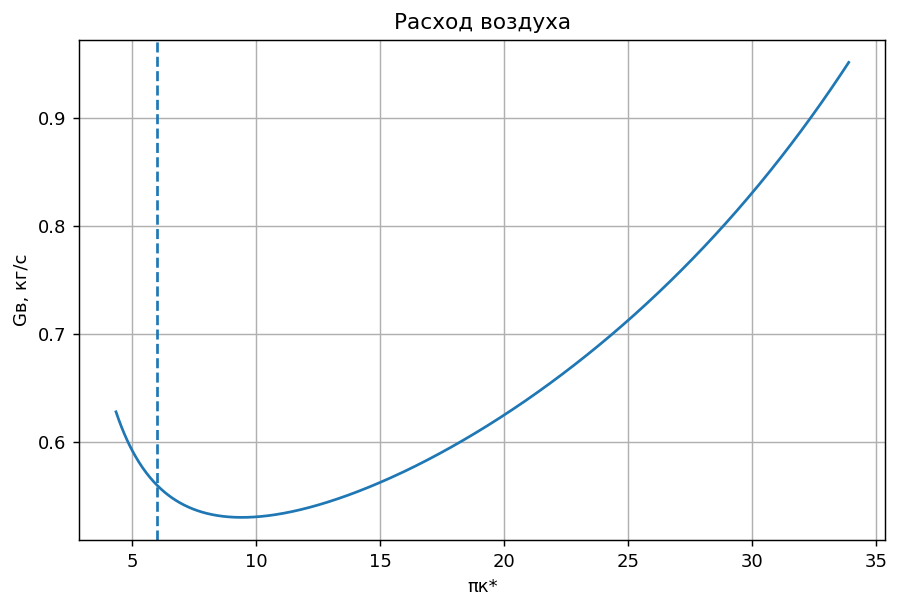

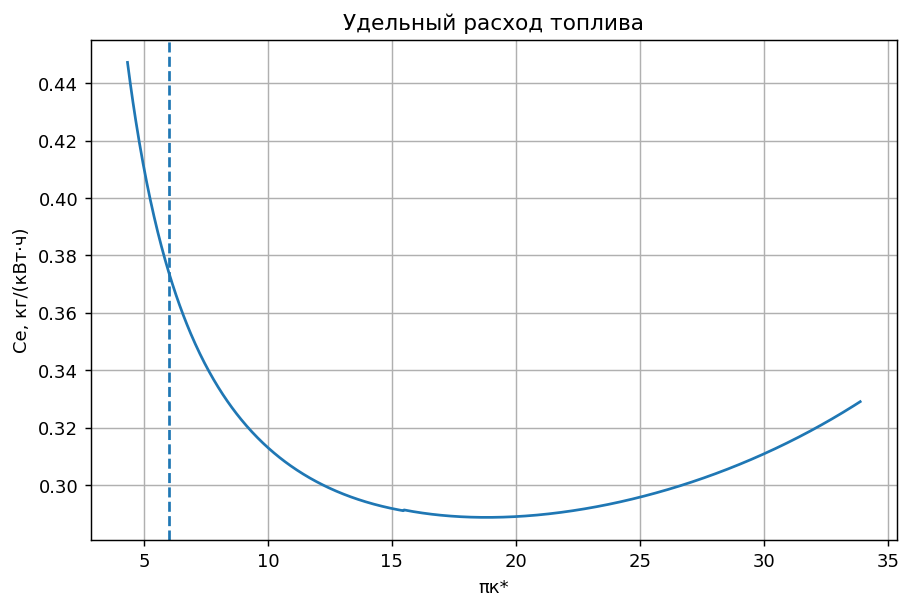

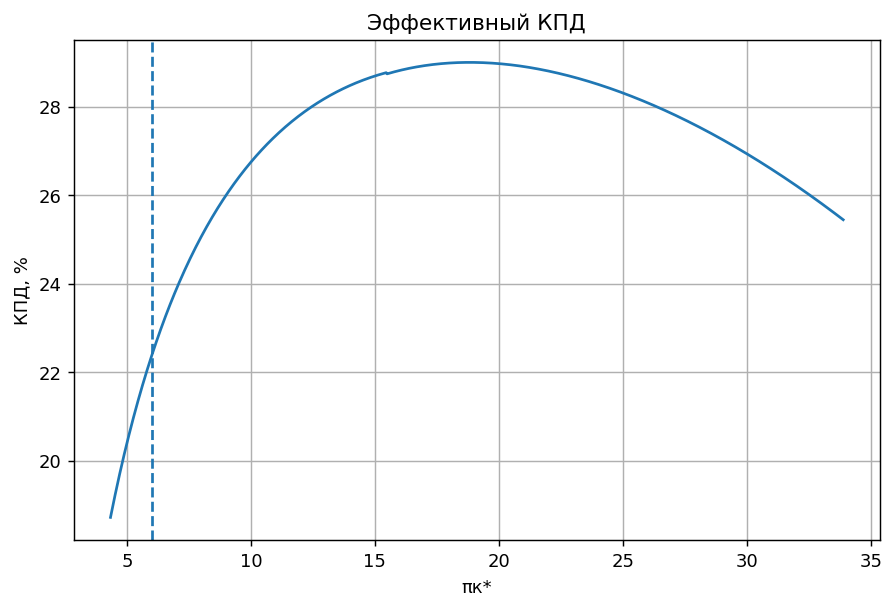

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['G_air'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Gв, кг/с')
plt.title('Расход воздуха')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['Ce_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Ce, кг/(кВт·ч)')
plt.title('Удельный расход топлива')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], 100*variants['eta_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('КПД, %')
plt.title('Эффективный КПД')
plt.grid()
plt.show()

# Часть II. Проектирование турбины компрессора и силовой турбины

Расчёт выполняется последовательно по направлению газа:

1. рассчитывается одноступенчатая турбина компрессора (ТК);
2. её выходные полные параметры передаются на вход одноступенчатой силовой турбины (СТ);
3. расход газа уточняется из баланса мощности СТ;
4. обе ступени проверяются совместно.

Для обеих турбин используется одна втулка $D_{\mathrm{вт}}=\mathrm{const}$. Подобранные параметры и критерий выбора из исходного файла сохранены.

## 15. Ограничения и расчётные коэффициенты

В этом блоке задаются только физические и конструктивные фильтры. Они не используются как целевая функция и не заставляют программу подгонять все параметры под один заранее выбранный результат.

Расширенный диапазон относительной высоты:

$$
\frac19\le\frac{l_i}{D_{\mathrm{ср},i}}\le\frac13,
\qquad l_i\ge15\ \text{мм}.
$$

По формулам (63) и последующему преобразованию на стр. 58–59 методички напряжение растяжения у корня РК и предельная по прочности частота определяются как

$$
\sigma_l=k_n n^2A_T,
\qquad
n_{\mathrm{кр}}=\sqrt{\frac{\sigma_{\mathrm{доп}}}{k_nA_T}},
$$

где $A_T=\pi D_2l_2=Gv_2/c_{2a}$ — площадь кольцевого сечения за РК, $n$ — об/мин, $\sigma_l$ — МПа. При $k_n=6{,}8\cdot10^{-6}$ выполняется эквивалентная оценка

$$
\sigma_l\approx78\frac{l_2}{D_2}\left(\frac{u_2}{100}\right)^2.
$$

Вариант проходит прочностной фильтр только при одновременном выполнении

$$
\sigma_l<\sigma_{\mathrm{доп}},\qquad n<n_{\mathrm{кр}}.
$$

Здесь $n_{\mathrm{кр}}$ — предельная частота по прочности лопатки, а не частота изгибных колебаний ротора.

In [15]:
import copy
import itertools
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
from scipy.stats import qmc
from IPython.display import display, Markdown
from IPython.utils.capture import capture_output

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 240)
pd.set_option('display.float_format', '{:.4f}'.format)

# Меняется вручную перед обсуждением с преподавателем. Это цель отбора, а не жёсткий фильтр.
TARGET_RPM = 70000.0

LIMITS = {
    'l_min_mm': 15.0,
    'l_good_ST_mm': 20.0,
    'lD_min': 1/9,
    'lD_max': 1/3,
    'eta_l_desired': 0.89,
    'sigma_max': 300.0,
    'gamma_max': 12.0,
    'rho_root_min': 0.10,
    'M_c1_max': 1.0,
    'M_w2_max': 1.0,
    'alpha1': (14.0, 25.0),
    'alpha2_TK': (70.0, 90.0),
    'alpha2_ST': (89.0, 90.0),
    'c0_ST_min': 130.0,
    'c2_ST': (200.0, 300.0),
    'pi_t_max': 3.0,
}

COEF = {
    'phi': 0.97,
    'psi': 0.97,
    'delta_mm': 0.4,
    'shroud': False,
    'eps': 1.0,
    'lb_c': 2.25,
    'lb_l': 2.75,
    'gap_c': 0.22,
    'gap_l': 0.30,
    'k_n': 6.8e-6,
    'k_sigma': 78.0,
    'sigma_tr': 1.0,
    'L_duct_mm': 25.0,
}

## 16. Пространство вариантов

Вместо подгонки одного решения задаётся широкая семимерная область. В ней независимо меняются:

- $D_{\mathrm{вт}}=60\ldots85$ мм в основном переборе;
- $(u/c_0)_{\mathrm{ТК}}$ и $(u/c_0)_{\mathrm{СТ}}$ от 0,55 до 0,64;
- $\alpha_1=14\ldots25^\circ$;
- $\alpha_{2,\mathrm{ТК}}=70\ldots90^\circ$;
- $\alpha_{2,\mathrm{СТ}}=89\ldots90^\circ$.

Реактивность не назначается независимо:

$$
\rho=f(u/c_0)=\frac{u/c_0-0{,}4497}{0{,}3835}.
$$

`TARGET_RPM` — желаемая частота вращения. Сейчас она равна 70 000 об/мин. Это не новый жёсткий фильтр: сначала проверяются все условия методики, затем среди допустимых вариантов находится ближайший к цели.

Поиск состоит из трёх частей:

1. Latin Hypercube равномерно покрывает всю семимерную область; число точек задаётся `N_SEARCH_SAMPLES`, а `SEARCH_SEED` позволяет воспроизвести выборку.
2. Систематический срез перебирает заданные уровни углов и $u/c_0$ около рабочей области.
3. `LOW_SPEED_PROBES` проверяет увеличенные диаметры вплоть до 100 мм. Эти варианты нужны для диагностики границы: обороты уменьшаются, но лопатки могут стать короче 15 мм или нарушить $l/D_{\mathrm{ср}}\ge1/9$.

Контрольный вариант добавляется для сравнения. Единой скрытой функции `score` нет: жёсткие фильтры, близость к целевым оборотам и остальные показатели выводятся отдельно.


In [16]:
SEARCH_SPACE = {
    'D_hub_mm': (60.0, 85.0),
    'TK_uc0': (0.55, 0.64),
    'TK_alpha1': (14.0, 25.0),
    'TK_alpha2': (70.0, 90.0),
    'ST_uc0': (0.55, 0.64),
    'ST_alpha1': (14.0, 25.0),
    'ST_alpha2': (89.0, 90.0),
}

N_SEARCH_SAMPLES = 100
SEARCH_SEED = 20261113
SEARCH_SETTINGS = {'TK_n_guess': 101000.0, 'ST_n_guess': 88000.0}

REFERENCE_DESIGN = {
    'D_hub_mm': 72.9,
    'TK': {'uc0': 0.622275, 'alpha1': 14.0, 'alpha2': 87.0, 'n_guess': 102000.0},
    'ST': {'uc0': 0.600000, 'alpha1': 22.6, 'alpha2': 90.0, 'n_guess': 84500.0},
}


# Специальные точки около низкооборотной границы. Часть из них намеренно
# не проходит фильтры: это показывает, какое именно условие мешает выйти на 70 тыс. об/мин.
LOW_SPEED_PROBES = [
    {'D_hub_mm': 74.0,
     'TK': {'uc0': 0.622275, 'alpha1': 14.0, 'alpha2': 84.0, 'n_guess': 100000.0},
     'ST': {'uc0': 0.622275, 'alpha1': 23.0, 'alpha2': 90.0, 'n_guess': 88000.0}},
    {'D_hub_mm': 74.0,
     'TK': {'uc0': 0.622275, 'alpha1': 14.0, 'alpha2': 86.0, 'n_guess': 100000.0},
     'ST': {'uc0': 0.622275, 'alpha1': 23.0, 'alpha2': 90.0, 'n_guess': 88000.0}},
    {'D_hub_mm': 74.0,
     'TK': {'uc0': 0.640000, 'alpha1': 14.0, 'alpha2': 84.0, 'n_guess': 103000.0},
     'ST': {'uc0': 0.622275, 'alpha1': 23.0, 'alpha2': 90.0, 'n_guess': 88000.0}},
    {'D_hub_mm': 78.0,
     'TK': {'uc0': 0.622275, 'alpha1': 14.0, 'alpha2': 84.0, 'n_guess': 95000.0},
     'ST': {'uc0': 0.622275, 'alpha1': 23.0, 'alpha2': 90.0, 'n_guess': 84000.0}},
    {'D_hub_mm': 82.0,
     'TK': {'uc0': 0.622275, 'alpha1': 14.0, 'alpha2': 84.0, 'n_guess': 90000.0},
     'ST': {'uc0': 0.622275, 'alpha1': 23.0, 'alpha2': 90.0, 'n_guess': 80000.0}},
    {'D_hub_mm': 99.5,
     'TK': {'uc0': 0.611870, 'alpha1': 14.0, 'alpha2': 72.5, 'n_guess': 76000.0},
     'ST': {'uc0': 0.609381, 'alpha1': 21.5, 'alpha2': 89.5, 'n_guess': 70000.0}},
]

def generate_search_designs(n_samples=N_SEARCH_SAMPLES, seed=SEARCH_SEED):
    keys = list(SEARCH_SPACE)
    bounds = np.array([SEARCH_SPACE[k] for k in keys], dtype=float)
    sample = qmc.LatinHypercube(d=len(keys), seed=seed).random(n_samples)
    values = qmc.scale(sample, bounds[:, 0], bounds[:, 1])
    designs = [copy.deepcopy(REFERENCE_DESIGN)]
    for row in values:
        p = dict(zip(keys, row))
        designs.append({
            'D_hub_mm': round(float(p['D_hub_mm']) * 2) / 2,
            'TK': {
                'uc0': round(float(p['TK_uc0']), 6),
                'alpha1': round(float(p['TK_alpha1']) * 2) / 2,
                'alpha2': round(float(p['TK_alpha2']) * 2) / 2,
                'n_guess': SEARCH_SETTINGS['TK_n_guess'],
            },
            'ST': {
                'uc0': round(float(p['ST_uc0']), 6),
                'alpha1': round(float(p['ST_alpha1']) * 2) / 2,
                'alpha2': round(float(p['ST_alpha2']) * 4) / 4,
                'n_guess': SEARCH_SETTINGS['ST_n_guess'],
            },
        })
    # Систематический срез чувствительности: все комбинации выбранных уровней
    # считаются одинаково, без целевой функции и без изменения фильтров.
    for dh, x_tk, x_st, a1_st, a2_tk, a2_st in itertools.product(
        (72.0, 73.0, 74.0),
        (0.600000, 0.622275),
        (0.600000, 0.622275),
        (21.0, 22.0),
        (70.0, 75.0, 80.0, 85.0, 87.0, 90.0),
        (89.0, 90.0),
    ):
        designs.append({
            'D_hub_mm': dh,
            'TK': {'uc0': x_tk, 'alpha1': 14.0, 'alpha2': a2_tk,
                   'n_guess': SEARCH_SETTINGS['TK_n_guess']},
            'ST': {'uc0': x_st, 'alpha1': a1_st, 'alpha2': a2_st,
                   'n_guess': SEARCH_SETTINGS['ST_n_guess']},
        })
    designs.extend(copy.deepcopy(LOW_SPEED_PROBES))
    unique = {}
    for d in designs:
        key = (d['D_hub_mm'], *(d['TK'][k] for k in ('uc0','alpha1','alpha2')),
               *(d['ST'][k] for k in ('uc0','alpha1','alpha2')))
        unique[key] = d
    return list(unique.values())

SEARCH_DESIGNS = generate_search_designs()
print(f'Сформировано вариантов для расчёта: {len(SEARCH_DESIGNS)}')

Сформировано вариантов для расчёта: 395


## 17. Передача параметров цикла в расчёт турбин

Из выбранной точки цикла $\pi_k^*=6$ передаются:

$$
T_g^*,\ p_g^*,\ L_{\mathrm{ТК}},\quad
T_4^*,\ p_4^*,\quad p_{5},\quad N_e.
$$

Потребная мощность силовой турбины до механического КПД и редуктора:

$$
N_{\mathrm{СТ}}=\frac{N_e}{\eta_{m,\mathrm{СТ}}\eta_r}.
$$

После расчёта ступеней расход согласуется по выражению

$$
G_g=\frac{N_{\mathrm{СТ}}}{L_{\mathrm{СТ}}}.
$$

Функция `set_cycle_eta()` затем подставляет полученные КПД и выходную скорость обратно в цикл, чтобы таблица цикла и расчёт ступеней использовали согласованные значения.

In [17]:
pi_k_selected = 6.0
s_base = cycle(pi_k_selected)
cyc = globals()
PI_K = pi_k_selected
R = R_gas * 1000.0
GAS_AIR = s_base['gas_air']
N_ST = power_kw / (eta_m_pt * eta_red) * 1e3
P_EXIT = s_base['p5'] * 1e3
TK_IN = dict(T0=s_base['Tg'], p0=s_base['pg'] * 1e3, L=s_base['L_gg'] * 1e3,
             cp=s_base['cp_gg'] * 1e3, k=s_base['k_gg'])
CYC_BASE = {k: globals()[k] for k in ('eta_gg_poly', 'eta_pt_poly', 'c_pt_exit')}

def reset_cycle():
    globals().update(CYC_BASE)
    return cycle(PI_K)

def st_inlet(rt):
    return dict(T0=rt['T2_tot'], p0=rt['p2_tot'] * COEF['sigma_tr'], p2=P_EXIT,
                cp=s_base['cp_pt'] * 1e3, k=s_base['k_pt'])

def set_cycle_eta(eta_tk, eta_st, c2_st, tol=1e-9):
    global eta_gg_poly, eta_pt_poly, c_pt_exit
    c_pt_exit = c2_st
    for _ in range(100):
        ss = cycle(PI_K)
        d_tk, d_st = eta_tk - ss['eta_gg'], eta_st - ss['eta_pt']
        eta_gg_poly += d_tk
        eta_pt_poly += d_st
        if max(abs(d_tk), abs(d_st)) < tol:
            break
    return cycle(PI_K)

def cycle_table(ss):
    return pd.DataFrame({
        'Турбина компрессора': [ss['G_gas'], ss['Tg'], ss['pg'], ss['T4'], ss['p4'], ss['pi_gg'], ss['L_gg'], ss['eta_gg']],
        'Силовая турбина': [ss['G_gas'], ss['T4'], ss['p4'], ss['T5_total'], ss['p5_total'], ss['pi_pt'], ss['L_pt'], ss['eta_pt']],
    }, index=['G газа, кг/с', 'T* вход, K', 'p* вход, кПа', 'T* выход, K', 'p* выход, кПа',
              'π*', 'L, кДж/кг', 'η* (адиаб.)'])

print(f"πк* = {PI_K:.1f}; Gв = {s_base['G_air']:.4f} кг/с; Tг* = {s_base['Tg']:.0f} K")
print(f"LТК = {TK_IN['L']/1e3:.2f} кДж/кг; NСТ = {N_ST/1e3:.2f} кВт; p за СТ = {P_EXIT/1e3:.2f} кПа")
display(cycle_table(s_base).round(4))

πк* = 6.0; Gв = 0.5600 кг/с; Tг* = 1250 K
LТК = 233.33 кДж/кг; NСТ = 113.71 кВт; p за СТ = 105.35 кПа


,Турбина компрессора,Силовая турбина
"G газа, кг/с",0.5687,0.5687
"T* вход, K",1250.0000,1057.3630
"p* вход, кПа",577.7291,264.2799
"T* выход, K",1057.3630,887.1996
"p* выход, кПа",264.2799,119.2852
π*,2.1861,2.2155
"L, кДж/кг",233.3292,199.9632
η* (адиаб.),0.9082,0.9085


## 18. Газодинамический расчёт одной ступени на среднем радиусе

### 18.1. Распределение теплоперепада и выход из СА

При заданной реактивности $\rho$ теплоперепад соплового аппарата:

$$
H_c=(1-\rho)H_0,\qquad c_1=\varphi\sqrt{2H_c}.
$$

Статические параметры за СА:

$$
T_1=T_0^*-\frac{c_1^2}{2c_p},\qquad
T_{1s}=T_0^*-\frac{H_c}{c_p},\qquad
p_1=p_0^*\left(\frac{T_{1s}}{T_0^*}\right)^{k/(k-1)}.
$$

Составляющие абсолютной скорости и площадь:

$$
c_{1u}=c_1\cos\alpha_1,\qquad c_{1a}=c_1\sin\alpha_1,
\qquad A_1=\frac{Gv_1}{c_{1a}}.
$$

Для постоянной втулки площадь кольца выражается через высоту:

$$
A=\pi(D_{\mathrm{вт}}+l)l,qquad
l=\frac{-D_{\mathrm{вт}}+\sqrt{D_{\mathrm{вт}}^2+4A/\pi}}{2}.
$$

### 18.2. Рабочее колесо

Окружная и относительная скорости на входе:

$$
u_1=\frac{\pi nD_1}{60},\qquad
w_1=\sqrt{(c_{1u}-u_1)^2+c_{1a}^2}.
$$

Теплоперепад РК и давление за ним:

$$
H_l=\rho H_0\frac{T_1}{T_{1s}},\qquad
p_2=p_1\left(\frac{T_1-H_l/c_p}{T_1}\right)^{k/(k-1)}.
$$

Выходная относительная скорость:

$$
w_2=\psi\sqrt{w_1^2+2H_l+u_2^2-u_1^2}.
$$

$u_2$, $c_{2a}$ и $l_2$ связаны между собой, поэтому код замыкает их итерацией из условия

$$
u_2=\frac{\pi n(D_{\mathrm{вт}}+l_2)}{60},\qquad
A_2=\frac{Gv_2}{c_{2a}}.
$$

### 18.3. Работа, потери и КПД

В принятой системе знаков выходная закрутка направлена против вращения, поэтому работа Эйлера записана как

$$
L_u=c_{1u}u_1+c_{2u}u_2.
$$

Полезная работа ступени:

$$
L_T=L_u-h_z-h_{тв},
$$

где $h_z$ — потеря от радиального зазора, $h_{тв}$ — потеря на трение диска. Лопаточный КПД:

$$
\eta_l=\frac{L_u}{H_0}-\frac{h_z}{H_0}+\frac{c_2^2/2}{H_0}.
$$

Для ТК код подбирает $H_0$ по условию $L_T=L_{\mathrm{ТК}}$. Для СТ $H_0$ определяется по заданному статическому давлению за ступенью. После получения площади $A_T=\pi D_2l_2$ рассчитываются $\sigma_l$, $n_{\mathrm{кр}}$ и запас $K_n=n_{\mathrm{кр}}/n$. После получения площади $A_T=\pi D_2l_2$ рассчитываются $\sigma_l$, $n_{\mathrm{кр}}$ и запас $K_n=n_{\mathrm{кр}}/n$.

In [18]:
def stage(inp, G, D_hub, n, rho, alpha1, alpha2, coef=None, n_bis=40):
    # Одноступенчатая турбина при D_вт = const. Все величины в СИ, углы в градусах.
    # inp: T0, p0 (параметры торможения на входе), cp, k и ОДНО из:
    #   'L'  — заданная удельная работа ступени (ТК, пп. 13–25);
    #   'p2' — заданное статическое давление за ступенью (СТ, пп. 1–12, 140).
    # Аргументы D_hub, n, rho, alpha1, alpha2 могут быть массивами (перебор).
    coef = COEF if coef is None else coef
    T0, p0, cp, k = inp['T0'], inp['p0'], inp['cp'], inp['k']
    Dh, n, rho, a1, a2 = [np.asarray(x, float) for x in np.broadcast_arrays(D_hub, n, rho, alpha1, alpha2)]
    phi, psi = coef['phi'], coef['psi']
    delta = 0.0 if coef['shroud'] else coef['delta_mm'] / 1e3
    m = k / (k - 1)
    om = np.pi * n / 60                       # u = om·D
    a1r, a2r = np.radians(a1), np.radians(a2)
    ct2 = np.cos(a2r) / np.sin(a2r)

    def length(A):                            # π(D_вт + l)·l = A
        return 0.5 * (-Dh + np.sqrt(Dh**2 + 4 * A / np.pi))

    def run(H0, n_in=26):
        Hc = (1 - rho) * H0                                   # п. 72
        c1 = phi * np.sqrt(2 * Hc)                            # п. 74
        T1 = T0 - c1**2 / (2 * cp)                            # п. 77
        T1s = T0 - Hc / cp                                    # п. 78
        p1 = p0 * (T1s / T0) ** m                             # п. 79
        c1u, c1a = c1 * np.cos(a1r), c1 * np.sin(a1r)
        v1 = R * T1 / p1                                      # п. 81
        l1 = length(G * v1 / c1a)                             # пп. 63, 82
        D1 = Dh + l1
        u1 = om * D1                                          # п. 87
        w1 = np.hypot(c1u - u1, c1a)                          # п. 84
        Hl = rho * H0 * T1 / T1s                              # п. 86
        p2 = p1 * ((T1 - Hl / cp) / T1) ** m                  # пп. 92, 93
        def exit_(u2):
            w2 = psi * np.sqrt(np.maximum(w1**2 + 2 * Hl + u2**2 - u1**2, 0.0))   # п. 90
            T2 = T1 - (w2**2 - w1**2 - u2**2 + u1**2) / (2 * cp)                    # п. 91
            v2 = R * T2 / p2                                                       # п. 94
            disc = u2**2 * ct2**2 - (1 + ct2**2) * (u2**2 - w2**2)
            c2a = (-u2 * ct2 + np.sqrt(disc)) / (1 + ct2**2)                       # пп. 96–99
            l2 = length(G * v2 / c2a)                                              # п. 95
            return w2, T2, v2, c2a, l2

        # u2 = πn(D_вт + l2)/60 (п. 88), а l2 зависит от u2 — решаем делением пополам.
        # Вилка ограничена l2 ≤ 0,6·D_вт (заведомо больше допустимого l/D = 1/3): так отсекается
        # второй, нефизичный корень с c2a → 0 и очень длинной лопаткой.
        lo_u, hi_u = om * Dh, om * 1.6 * Dh
        for _ in range(n_in):
            um = 0.5 * (lo_u + hi_u)
            too_big = ~(um - om * (Dh + exit_(um)[4]) < 0)        # NaN — u2 слишком велика
            lo_u, hi_u = np.where(too_big, lo_u, um), np.where(too_big, um, hi_u)
        u2 = 0.5 * (lo_u + hi_u)
        w2, T2, v2, c2a, l2 = exit_(u2)
        D2 = Dh + l2
        c2u = c2a * ct2
        Lu = c1u * u1 + c2u * u2                                                   # п. 101
        h_z = 1.37 * (1 + 1.6 * rho) * (1 + l2 / D2) * Lu * delta / l2            # п. 114
        rho_g = 0.5 * (1 / v1 + 1 / v2)
        N_tv = (1.07 * D2**2 + 61 * (1 - coef['eps']) * D2 * l2**1.5) * (u2 / 100) ** 3 * rho_g * 1e3  # п. 119, Вт
        h_tv = N_tv / G                                                            # п. 120
        LT = Lu - h_z - h_tv                                                       # пп. 116, 124
        return dict(H0=H0, Hc=Hc, Hl=Hl, c1=c1, c1u=c1u, c1a=c1a, T1=T1, p1=p1, v1=v1, l1=l1, D1=D1,
                    u1=u1, w1=w1, w2=w2, T2=T2, p2=p2, v2=v2, c2a=c2a, c2u=c2u, l2=l2, D2=D2, u2=u2,
                    Lu=Lu, h_z=h_z, h_tv=h_tv, N_tv=N_tv, LT=LT)

    if 'p2' in inp:
        # По пп. 77–93 p2 = p0*·(1 − H0/(cp·T0*))^(k/(k−1)), отсюда H0 при заданном p2 (п. 4, п. 140)
        H0 = np.full(Dh.shape, cp * T0 * (1 - (inp['p2'] / p0) ** (1 / m)))
        r = run(H0, n_in=50)
        r['converged'] = np.isfinite(r['LT']) & (np.abs(r['u2'] - om * r['D2']) < 0.01)
    else:
        L = inp['L']
        lo, hi = np.full(Dh.shape, 0.6 * L), np.full(Dh.shape, 2.5 * L)
        for _ in range(n_bis):                # H0 такое, что L_т = L
            mid = 0.5 * (lo + hi)
            up = ~(run(mid)['LT'] - L > 0)
            lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
        r = run(0.5 * (lo + hi), n_in=50)
        r['converged'] = (np.abs(r['LT'] - L) < 2.0) & (np.abs(r['u2'] - om * r['D2']) < 0.01)

    H0 = r['H0']
    c2 = np.hypot(r['c2a'], r['c2u'])                                              # п. 100
    r.update(D_hub=Dh, n=n, rho=rho, alpha1=a1, alpha2=a2, c2=c2, T0=np.full(Dh.shape, T0), p0=np.full(Dh.shape, p0), cp=np.full(Dh.shape, cp), k=np.full(Dh.shape, k))
    r['c0_ad'] = np.sqrt(2 * H0)                                                   # п. 26
    r['uc0'] = r['u2'] / r['c0_ad']
    r['beta1'] = np.degrees(np.arctan2(r['c1a'], r['c1u'] - r['u1']))              # п. 85
    r['beta2'] = np.degrees(np.arctan2(r['c2a'], r['c2u'] + r['u2']))              # п. 97
    r['turn'] = 180 - r['beta1'] - r['beta2']
    r['h_c'] = (1 / phi**2 - 1) * r['c1']**2 / 2                                   # п. 103
    r['h_l'] = (1 / psi**2 - 1) * r['w2']**2 / 2                                   # п. 107
    r['h_v'] = c2**2 / 2                                                           # п. 109
    for kk in ('h_c', 'h_l', 'h_v', 'h_z', 'h_tv'):
        r['xi' + kk[1:]] = r[kk] / H0                                              # пп. 105, 108, 110, 115, 121
    r['eta_u'] = r['Lu'] / H0                                                      # п. 102
    r['eta_T'] = r['LT'] / H0                                                      # мощностной, пп. 117, 122
    r['eta_l'] = r['eta_u'] - r['xi_z'] + r['xi_v']                                # лопаточный, п. 118
    r['eta_l_tv'] = r['eta_l'] - r['xi_tv']                                        # п. 123
    Tst = r['T2'] + (r['h_z'] + r['h_tv']) / cp                                    # п. 125
    r['T2_tot'] = Tst + c2**2 / (2 * cp)                                           # п. 126
    r['p2_tot'] = r['p2'] * (r['T2_tot'] / Tst) ** m                               # п. 127
    r['eta_tot'] = r['LT'] / (cp * T0 * (1 - (r['p2_tot'] / p0) ** (1 / m)))       # пп. 128, 129
    r['pi_tot'] = p0 / r['p2_tot']
    a1s, a2s = np.sqrt(k * R * r['T1']), np.sqrt(k * R * r['T2'])
    r['M_c1'], r['M_w1'] = r['c1'] / a1s, r['w1'] / a1s
    r['M_w2'], r['M_c2'] = r['w2'] / a2s, c2 / a2s
    r['lD1'], r['lD2'] = r['l1'] / r['D1'], r['l2'] / r['D2']
    r['A_T'] = np.pi * r['D2'] * r['l2']
    r['sigma_78'] = coef['k_sigma'] * r['lD2'] * (r['u2'] / 100) ** 2
    r['sigma'] = coef['k_n'] * r['n']**2 * r['A_T']
    r['n_crit'] = np.sqrt(LIMITS['sigma_max'] / (coef['k_n'] * r['A_T']))
    r['n_margin'] = r['n_crit'] / r['n']
    # Закон профилирования Γ=c1u·r=const и радиальное равновесие.
    rm = r['D1'] / 2
    rh = Dh / 2
    rt_tip = rh + r['l1']
    def rho_at_radius(radius):
        exponent = (r['c1u']**2 * rm**2) / (2 * R * r['T1']) * (1/rm**2 - 1/radius**2)
        p1_radius = r['p1'] * np.exp(exponent)
        T1_ad_radius = T0 * (p1_radius / p0) ** ((k - 1) / k)
        return cp * T1_ad_radius / H0 * (1 - (r['p2'] / p1_radius) ** ((k - 1) / k))
    r['rho_root'] = rho_at_radius(rh)
    r['rho_tip'] = rho_at_radius(rt_tip)
    r['b_c'], r['b_l'] = r['l1'] / coef['lb_c'], r['l2'] / coef['lb_l']
    r['s_c'], r['s_l'] = coef['gap_c'] * r['b_c'], coef['gap_l'] * r['b_l']
    r['gamma'] = np.degrees(np.arctan((r['l2'] - r['l1']) / (r['s_c'] + r['b_l'])))
    r['N'] = G * r['LT']
    r['G'] = np.full(Dh.shape, G)
    return r

## 19. Реактивность, частота вращения и совместные проверки

Для каждой независимо сгенерированной точки сначала вычисляется

$$
c_0=\sqrt{2H_0},\qquad x=\frac{u_2}{c_0},\qquad \rho=f(x).
$$

Функция `solve_stage_on_curve()` изменяет рабочую частоту $n$ до совпадения фактического и заданного $u_2/c_0$. После определения площади выхода РК прочностная частота вычисляется отдельно:

$$
n_{\mathrm{кр}}=\sqrt{\frac{\sigma_{\mathrm{доп}}}{k_nA_T}},
\qquad K_n=\frac{n_{\mathrm{кр}}}{n}.
$$

Значение $K_n>1$ означает выполнение приближённой проверки прочности. Чем больше $K_n$, тем дальше рабочая частота от предельной.

Приближённая реактивность у корня:

$$
\rho_{\mathrm{кор}}=1-(1-\rho_{\mathrm{ср}})
\left(\frac{D_1}{D_{\mathrm{вт}}}\right)^{2\varphi^2\cos^2\alpha_1}.
$$

После расчёта обеих ступеней проверяется последовательность

$$
l_{\mathrm{СА,ТК}}<l_{\mathrm{РК,ТК}}<l_{\mathrm{СА,СТ}}<l_{\mathrm{РК,СТ}}.
$$

In [19]:
def checks(r, name):
    # Булевы массивы «ограничение выполнено». name = 'TK' или 'ST'.
    Lm = LIMITS
    lmin = Lm['l_min_mm'] / 1e3
    c = {
        'расчёт сошёлся': r['converged'],
        'l1 ≥ l_min': r['l1'] >= lmin,
        'l2 ≥ l_min': r['l2'] >= lmin,
        'l1/D1 в диапазоне': (r['lD1'] >= Lm['lD_min']) & (r['lD1'] <= Lm['lD_max']),
        'l2/D2 в диапазоне': (r['lD2'] >= Lm['lD_min']) & (r['lD2'] <= Lm['lD_max']),
        'σ < σ_max': r['sigma'] < Lm['sigma_max'],
        '|γ| ≤ γ_max': np.abs(r['gamma']) <= Lm['gamma_max'],
        'ρ у корня ≥ min': r['rho_root'] >= Lm['rho_root_min'],
        'M_c1 ≤ max': r['M_c1'] <= Lm['M_c1_max'],
        'M_w2 ≤ max': r['M_w2'] <= Lm['M_w2_max'],
    }
    if name == 'ST':
        c['α2 СТ в диапазоне'] = (r['alpha2'] >= Lm['alpha2_ST'][0]) & (r['alpha2'] <= Lm['alpha2_ST'][1])
        c['c2 СТ в диапазоне'] = (r['c2'] >= Lm['c2_ST'][0]) & (r['c2'] <= Lm['c2_ST'][1])
    c['ηл ≥ желательного значения'] = r['eta_l'] >= Lm['eta_l_desired']
    return {k: np.nan_to_num(v, nan=False).astype(bool) for k, v in c.items()}


def scalar(r):
    return {k: float(np.ravel(v)[0]) for k, v in r.items()}

# Полином первого порядка по оцифрованным точкам рис. 18.
REACTION_POLY = np.polynomial.Polynomial([-0.4497 / 0.3835, 1.0 / 0.3835])

def rho_from_uc0(uc0):
    return float(REACTION_POLY(float(uc0)))

def solve_stage_on_curve(inp, G, D_hub, uc0_target, alpha1, alpha2, n_guess):
    rho = rho_from_uc0(uc0_target)
    if not (0.0 < rho < 0.75):
        raise ValueError('Точка u/c0 находится вне диапазона аппроксимации реактивности.')

    def residual(n):
        rr = scalar(stage(inp, G, D_hub, float(n), rho, alpha1, alpha2))
        return rr['uc0'] - uc0_target

    guesses = [(n_guess, n_guess * 1.002), (n_guess * 0.92, n_guess * 1.08)]
    solution = None
    for x0, x1 in guesses:
        try:
            trial = root_scalar(residual, x0=x0, x1=x1, method='secant', maxiter=20, xtol=1e-7)
            if trial.converged and 30000 <= trial.root <= 160000:
                rr = scalar(stage(inp, G, D_hub, trial.root, rho, alpha1, alpha2))
                if rr['converged'] and np.isfinite(rr['l2']) and abs(rr['uc0'] - uc0_target) < 1e-7:
                    solution = rr
                    break
        except (ValueError, OverflowError, ZeroDivisionError):
            pass
    if solution is None:
        raise ValueError('Не удалось согласовать частоту вращения с полиномом реактивности.')
    solution['uc0_target'] = float(uc0_target)
    solution['rho_poly'] = rho_from_uc0(solution['uc0'])
    solution['pi_static'] = solution['p0'] / solution['p2']
    return solution

def transition_values(rt, rs):
    c0a = rt['c2a']
    c0u = rt['c2u'] * rt['D2'] / rs['D1']
    c0 = math.hypot(c0a, c0u)
    gamma = math.degrees(math.atan((rs['l1'] - rt['l2']) / (COEF['L_duct_mm'] / 1000)))
    return c0, gamma

def pair_checks(rt, rs):
    heights = np.array([rt['l1'], rt['l2'], rs['l1'], rs['l2']])
    c0_st, gamma_duct = transition_values(rt, rs)
    hard = {
        'Расчёт обеих ступеней сошёлся': bool(rt['converged'] and rs['converged']),
        'Каждая следующая лопатка длиннее предыдущей': bool(np.all(np.diff(heights) > 0)),
        'Все лопатки не короче 15 мм': bool(np.all(heights >= LIMITS['l_min_mm']/1000)),
        'l/Dср всех венцов в пределах 1/9–1/3': all(LIMITS['lD_min'] <= r[k] <= LIMITS['lD_max'] for r in (rt, rs) for k in ('lD1', 'lD2')),
        'Углы раскрытия ТК, перехода и СТ от 0 до 12°': all(0 <= g <= LIMITS['gamma_max'] for g in (rt['gamma'], gamma_duct, rs['gamma'])),
        'Реактивность вычислена по полиному': all(abs(r['rho'] - r['rho_poly']) < 1e-8 for r in (rt, rs)),
        'Реактивность у корня не меньше 0,10': all(r['rho_root'] >= LIMITS['rho_root_min'] for r in (rt, rs)),
        'Напряжение в обеих ступенях меньше 300 МПа': all(r['sigma'] < LIMITS['sigma_max'] for r in (rt, rs)),
        'Рабочая частота ниже n_кр в обеих ступенях': all(r['n'] < r['n_crit'] for r in (rt, rs)),
        'Рабочая частота ниже n_кр в обеих ступенях': all(r['n'] < r['n_crit'] for r in (rt, rs)),
        'Степень расширения каждой турбины меньше 3': all(r['pi_static'] < LIMITS['pi_t_max'] for r in (rt, rs)),
        'α1 обеих ступеней в пределах 14–25°': all(LIMITS['alpha1'][0] <= r['alpha1'] <= LIMITS['alpha1'][1] for r in (rt, rs)),
        'α2 ТК в пределах 70–90°': LIMITS['alpha2_TK'][0] <= rt['alpha2'] <= LIMITS['alpha2_TK'][1],
        'α2 СТ в пределах 89–90°': LIMITS['alpha2_ST'][0] <= rs['alpha2'] <= LIMITS['alpha2_ST'][1],
        'Скорость на входе СТ не меньше 130 м/с': c0_st >= LIMITS['c0_ST_min'],
        'Скорость за СТ в пределах 200–300 м/с': LIMITS['c2_ST'][0] <= rs['c2'] <= LIMITS['c2_ST'][1],
        'Числа Маха не больше 1': all(max(r['M_c1'], r['M_w2']) <= 1 for r in (rt, rs)),
    }
    desired = {
        'Лопаточный КПД обеих ступеней не меньше 0,89': all(r['eta_l'] >= LIMITS['eta_l_desired'] for r in (rt, rs)),
        'Рабочая лопатка СТ около или выше 20 мм': rs['l2'] >= LIMITS['l_good_ST_mm']/1000,
    }
    return hard, desired

## 20. Расчёт и фильтрация вариантов

Для каждого варианта выполняется одинаковый расчёт без целевой функции:

1. рассчитывается ТК;
2. её выходные полные параметры передаются в СТ;
3. расход согласуется из $G_g=N_{\mathrm{СТ}}/L_{\mathrm{СТ}}$;
4. записываются все рассчитанные параметры;
5. каждый физический фильтр проверяется независимо.

Программа не увеличивает искусственно рейтинг варианта за близость к одному заранее назначенному сочетанию. После фильтрации формируются несколько независимых подборок: минимальное напряжение, максимальный запас по $n_{\mathrm{кр}}$, максимальный минимальный КПД, максимальные лопатки и Парето-фронт.

In [20]:
def evaluate_curve_design(design, G, n_tk=None, n_st=None):
    Dh = design['D_hub_mm'] / 1000
    t, q = design['TK'], design['ST']
    rt = solve_stage_on_curve(TK_IN, G, Dh, t['uc0'], t['alpha1'], t['alpha2'], n_tk or t['n_guess'])
    rs = solve_stage_on_curve(st_inlet(rt), G, Dh, q['uc0'], q['alpha1'], q['alpha2'], n_st or q['n_guess'])
    return rt, rs

def couple_curve_design(design, G0=0.615, n_iter=18, tol=2e-7, update_cycle=True):
    G = float(G0)
    nt, ns_ = design['TK']['n_guess'], design['ST']['n_guess']
    history = []
    for iteration in range(n_iter):
        rt, rs = evaluate_curve_design(design, G, nt, ns_)
        nt, ns_ = rt['n'], rs['n']
        G_new = N_ST / rs['LT']
        history.append({'итерация': iteration, 'G газа, кг/с': G, 'G новое, кг/с': G_new,
                        'n ТК, об/мин': nt, 'n СТ, об/мин': ns_, 'L СТ, кДж/кг': rs['LT']/1000})
        if abs(G_new - G) < tol:
            G = G_new
            break
        G += 0.65 * (G_new - G)
    rt, rs = evaluate_curve_design(design, G, nt, ns_)
    hard, desired = pair_checks(rt, rs)
    ss = None
    if update_cycle:
        reset_cycle()
        ss = set_cycle_eta(rt['eta_tot'], rs['eta_tot'], rs['c2'])
    return ss, rt, rs, pd.DataFrame(history).set_index('итерация'), hard, desired

def record_from_result(case_id, design, rt, rs, history, hard, desired):
    c0_st, gamma_duct = transition_values(rt, rs)
    heights = [rt['l1'], rt['l2'], rs['l1'], rs['l2']]
    return {
        'case_id': int(case_id), 'design': design, 'rt': rt, 'rs': rs, 'history': history,
        'hard_checks': hard, 'hard_ok': all(hard.values()),
        'failed_hard': [name for name, ok in hard.items() if not ok],
        'D_вт, мм': design['D_hub_mm'],
        'u/c0 ТК': rt['uc0'], 'u/c0 СТ': rs['uc0'], 'ρ ТК': rt['rho'], 'ρ СТ': rs['rho'],
        'α1 ТК': rt['alpha1'], 'α2 ТК': rt['alpha2'], 'α1 СТ': rs['alpha1'], 'α2 СТ': rs['alpha2'],
        'ηл ТК': rt['eta_l'], 'ηл СТ': rs['eta_l'], 'ηл min': min(rt['eta_l'], rs['eta_l']),
        'l СА ТК, мм': 1000*rt['l1'], 'l РК ТК, мм': 1000*rt['l2'],
        'l СА СТ, мм': 1000*rs['l1'], 'l РК СТ, мм': 1000*rs['l2'],
        'l min, мм': 1000*min(heights),
        'l/D РК ТК': rt['lD2'], 'l/D РК СТ': rs['lD2'],
        'n ТК': rt['n'], 'nкр ТК': rt['n_crit'], 'K_n ТК': rt['n_margin'],
        'n СТ': rs['n'], 'nкр СТ': rs['n_crit'], 'K_n СТ': rs['n_margin'],
        '|n ТК − nц|': abs(rt['n'] - TARGET_RPM), '|n СТ − nц|': abs(rs['n'] - TARGET_RPM),
        'Δn max': max(abs(rt['n'] - TARGET_RPM), abs(rs['n'] - TARGET_RPM)),
        'n max': max(rt['n'], rs['n']), 'обе n ≤ nц': max(rt['n'], rs['n']) <= TARGET_RPM,
        'K_n min': min(rt['n_margin'], rs['n_margin']),
        'A_T ТК, м²': rt['A_T'], 'A_T СТ, м²': rs['A_T'],
        'σ ТК, МПа': rt['sigma'], 'σ СТ, МПа': rs['sigma'],
        'σ max, МПа': max(rt['sigma'], rs['sigma']),
        'γ ТК, °': rt['gamma'], 'γ перехода, °': gamma_duct, 'γ СТ, °': rs['gamma'],
        'c0 СТ, м/с': c0_st, 'c2 СТ, м/с': rs['c2'],
        'πт ТК': rt['pi_static'], 'πт СТ': rs['pi_static'],
        'eta_desired': all(desired.values()),
    }

In [21]:
def search_designs(designs=SEARCH_DESIGNS):
    records = []
    for case_id, design in enumerate(designs):
        try:
            _, rt, rs, hist, hard, desired = couple_curve_design(design, update_cycle=False)
        except (ValueError, OverflowError, ZeroDivisionError):
            continue
        records.append(record_from_result(case_id, design, rt, rs, hist, hard, desired))
    return records

def pareto_front(records):
    front = []
    for candidate in records:
        dominated = False
        for other in records:
            no_worse = (other['σ max, МПа'] <= candidate['σ max, МПа'] and
                        other['ηл min'] >= candidate['ηл min'] and
                        other['l min, мм'] >= candidate['l min, мм'])
            strictly_better = (other['σ max, МПа'] < candidate['σ max, МПа'] or
                               other['ηл min'] > candidate['ηл min'] or
                               other['l min, мм'] > candidate['l min, мм'])
            if no_worse and strictly_better:
                dominated = True
                break
        if not dominated:
            front.append(candidate)
    return front

def select_interesting(records):
    if not records:
        return []
    choices = []
    criteria = [
        (f'ближайший к {TARGET_RPM:,.0f} об/мин', min(records, key=lambda r: r['Δn max'])),
        ('минимальная максимальная частота', min(records, key=lambda r: r['n max'])),
        ('минимальное максимальное напряжение', min(records, key=lambda r: r['σ max, МПа'])),
        ('максимальный запас nкр/n', max(records, key=lambda r: r['K_n min'])),
        ('максимальный минимальный ηл', max(records, key=lambda r: r['ηл min'])),
        ('максимальная минимальная лопатка', max(records, key=lambda r: r['l min, мм'])),
        ('максимальная лопатка РК СТ', max(records, key=lambda r: r['l РК СТ, мм'])),
    ]
    seen = set()
    for label, row in criteria:
        if row['case_id'] not in seen:
            item = row.copy(); item['интерес'] = label
            choices.append(item); seen.add(row['case_id'])
    for row in sorted(pareto_front(records), key=lambda r: r['case_id']):
        if row['case_id'] not in seen and len(choices) < 10:
            item = row.copy(); item['интерес'] = 'Парето: σ / ηл / высота'
            choices.append(item); seen.add(row['case_id'])
    return choices

### 20.1. Запуск расчёта и независимые фильтры

Сначала сохраняются все рассчитываемые варианты. Затем отбираются варианты, прошедшие каждый жёсткий фильтр. Целевые обороты не подменяют эти фильтры.

Ноутбук отдельно показывает:

- ближайший к `TARGET_RPM` допустимый вариант;
- ближайший рассчитанный вариант независимо от фильтров и причины его отклонения;
- существует ли вариант, у которого обе частоты не превышают целевое значение.


In [22]:
SEARCH_RESULTS = search_designs()
if not SEARCH_RESULTS:
    raise RuntimeError('В заданном пространстве не найдено рассчитываемых вариантов.')

feasible = [row for row in SEARCH_RESULTS if row['hard_ok']]
if not feasible:
    raise RuntimeError('Ни один рассчитанный вариант не прошёл все жёсткие фильтры. Изучите таблицу отказов.')

failure_counts = {}
for row in SEARCH_RESULTS:
    for name in row['failed_hard']:
        failure_counts[name] = failure_counts.get(name, 0) + 1

INTERESTING_RECORDS = select_interesting(feasible)
REFERENCE_RECORD = next((r for r in SEARCH_RESULTS if r['case_id'] == 0), None)
CLOSEST_FEASIBLE_TO_TARGET = min(feasible, key=lambda r: r['Δn max'])
CLOSEST_CALCULATED_TO_TARGET = min(SEARCH_RESULTS, key=lambda r: r['Δn max'])
AT_OR_BELOW_TARGET = [r for r in feasible if r['обе n ≤ nц']]

print(f'Запланировано вариантов: {len(SEARCH_DESIGNS)}')
print(f'Рассчитано вариантов: {len(SEARCH_RESULTS)}')
print(f'Прошли все жёсткие фильтры: {len(feasible)}')
print(f'Выбрано интересных вариантов для сравнения: {len(INTERESTING_RECORDS)}')
display(pd.Series(failure_counts, name='Число отклонённых вариантов').sort_values(ascending=False).to_frame())

print(f'Целевая частота: {TARGET_RPM:,.0f} об/мин')
print(f'Допустимых вариантов с обеими частотами ≤ цели: {len(AT_OR_BELOW_TARGET)}')
diagnostic_rows = []
for label, row in (
    ('Ближайший допустимый', CLOSEST_FEASIBLE_TO_TARGET),
    ('Ближайший рассчитанный', CLOSEST_CALCULATED_TO_TARGET),
):
    diagnostic_rows.append({
        'Статус': label, 'case_id': row['case_id'], 'Dвт, мм': row['D_вт, мм'],
        'n ТК, об/мин': row['n ТК'], 'n СТ, об/мин': row['n СТ'],
        'max|n−nц|, об/мин': row['Δn max'], 'Фильтры пройдены': row['hard_ok'],
        'Причины отклонения': '—' if row['hard_ok'] else '; '.join(row['failed_hard']),
    })
display(pd.DataFrame(diagnostic_rows).set_index('Статус').round(2))


Запланировано вариантов: 395
Рассчитано вариантов: 301
Прошли все жёсткие фильтры: 1
Выбрано интересных вариантов для сравнения: 1
Целевая частота: 70,000 об/мин
Допустимых вариантов с обеими частотами ≤ цели: 0


,Число отклонённых вариантов
Рабочая частота ниже n_кр в обеих ступенях,272
Напряжение в обеих ступенях меньше 300 МПа,272
Все лопатки не короче 15 мм,267
"Углы раскрытия ТК, перехода и СТ от 0 до 12°",233
Каждая следующая лопатка длиннее предыдущей,84
"Реактивность у корня не меньше 0,10",59
Скорость за СТ в пределах 200–300 м/с,17
Числа Маха не больше 1,1
l/Dср всех венцов в пределах 1/9–1/3,1


,case_id,"Dвт, мм","n ТК, об/мин","n СТ, об/мин","max|n−nц|, об/мин",Фильтры пройдены,Причины отклонения
Статус,,,,,,,
Ближайший допустимый,0,72.9000,102268.2600,84655.9800,32268.2600,True,—
Ближайший рассчитанный,394,99.5000,75349.1900,69168.0700,5349.1900,False,Каждая следующая лопатка длиннее предыдущей; В...


### 20.2. Несколько интересных вариантов

Это не рейтинг по скрытой оценке. Первая строка показывает допустимый вариант, ближайший к `TARGET_RPM`; остальные строки выбираются по независимым критериям. `case_id` позволяет вручную перенести любую строку в подробный расчёт.


In [23]:
RESULT_COLUMNS = [
    'case_id', 'интерес', 'D_вт, мм', 'u/c0 ТК', 'u/c0 СТ', 'ρ ТК', 'ρ СТ',
    'α1 ТК', 'α2 ТК', 'α1 СТ', 'α2 СТ', 'ηл ТК', 'ηл СТ',
    'l СА ТК, мм', 'l РК ТК, мм', 'l СА СТ, мм', 'l РК СТ, мм',
    'l/D РК ТК', 'l/D РК СТ', 'n ТК', 'nкр ТК', 'K_n ТК',
    'n СТ', 'nкр СТ', 'K_n СТ', '|n ТК − nц|', '|n СТ − nц|', 'Δn max',
    'σ ТК, МПа', 'σ СТ, МПа',
    'γ ТК, °', 'γ перехода, °', 'γ СТ, °', 'c0 СТ, м/с', 'c2 СТ, м/с', 'πт ТК', 'πт СТ',
]
interesting_table = pd.DataFrame([{k: r[k] for k in RESULT_COLUMNS} for r in INTERESTING_RECORDS])
display(interesting_table.round(4))

print('Контрольный ранее выбранный вариант:')
if REFERENCE_RECORD is not None:
    reference_view = {k: REFERENCE_RECORD[k] for k in RESULT_COLUMNS if k not in ('интерес',)}
    display(pd.DataFrame([reference_view]).round(4))
    print('Проходит все фильтры:', REFERENCE_RECORD['hard_ok'])

Контрольный ранее выбранный вариант:
Проходит все фильтры: True


,case_id,интерес,"D_вт, мм",u/c0 ТК,u/c0 СТ,ρ ТК,ρ СТ,α1 ТК,α2 ТК,α1 СТ,α2 СТ,ηл ТК,ηл СТ,"l СА ТК, мм","l РК ТК, мм","l СА СТ, мм","l РК СТ, мм",l/D РК ТК,l/D РК СТ,n ТК,nкр ТК,K_n ТК,n СТ,nкр СТ,K_n СТ,|n ТК − nц|,|n СТ − nц|,Δn max,"σ ТК, МПа","σ СТ, МПа","γ ТК, °","γ перехода, °","γ СТ, °","c0 СТ, м/с","c2 СТ, м/с",πт ТК,πт СТ
0,0,"ближайший к 70,000 об/мин",72.9000,0.6223,0.6000,0.4500,0.3919,14.0000,87.0000,22.6000,90.0000,0.8769,0.8942,15.0145,15.0736,18.8383,20.8097,0.1713,0.2221,102268.2593,102907.3717,1.0062,84655.9832,84860.6974,1.0024,32268.2593,14655.9832,32268.2593,296.2852,298.5543,0.4876,8.5637,11.8333,182.0765,236.6325,2.4166,2.3970


,case_id,"D_вт, мм",u/c0 ТК,u/c0 СТ,ρ ТК,ρ СТ,α1 ТК,α2 ТК,α1 СТ,α2 СТ,ηл ТК,ηл СТ,"l СА ТК, мм","l РК ТК, мм","l СА СТ, мм","l РК СТ, мм",l/D РК ТК,l/D РК СТ,n ТК,nкр ТК,K_n ТК,n СТ,nкр СТ,K_n СТ,|n ТК − nц|,|n СТ − nц|,Δn max,"σ ТК, МПа","σ СТ, МПа","γ ТК, °","γ перехода, °","γ СТ, °","c0 СТ, м/с","c2 СТ, м/с",πт ТК,πт СТ
0,0,72.9000,0.6223,0.6000,0.4500,0.3919,14.0000,87.0000,22.6000,90.0000,0.8769,0.8942,15.0145,15.0736,18.8383,20.8097,0.1713,0.2221,102268.2593,102907.3717,1.0062,84655.9832,84860.6974,1.0024,32268.2593,14655.9832,32268.2593,296.2852,298.5543,0.4876,8.5637,11.8333,182.0765,236.6325,2.4166,2.3970


### 20.3. Карта допустимых вариантов

Графики показывают только варианты, прошедшие жёсткие фильтры. Справа внизу частоты ТК и СТ сравниваются с линиями `TARGET_RPM`; поэтому сразу видно, насколько целевые обороты достижимы без нарушения ограничений.


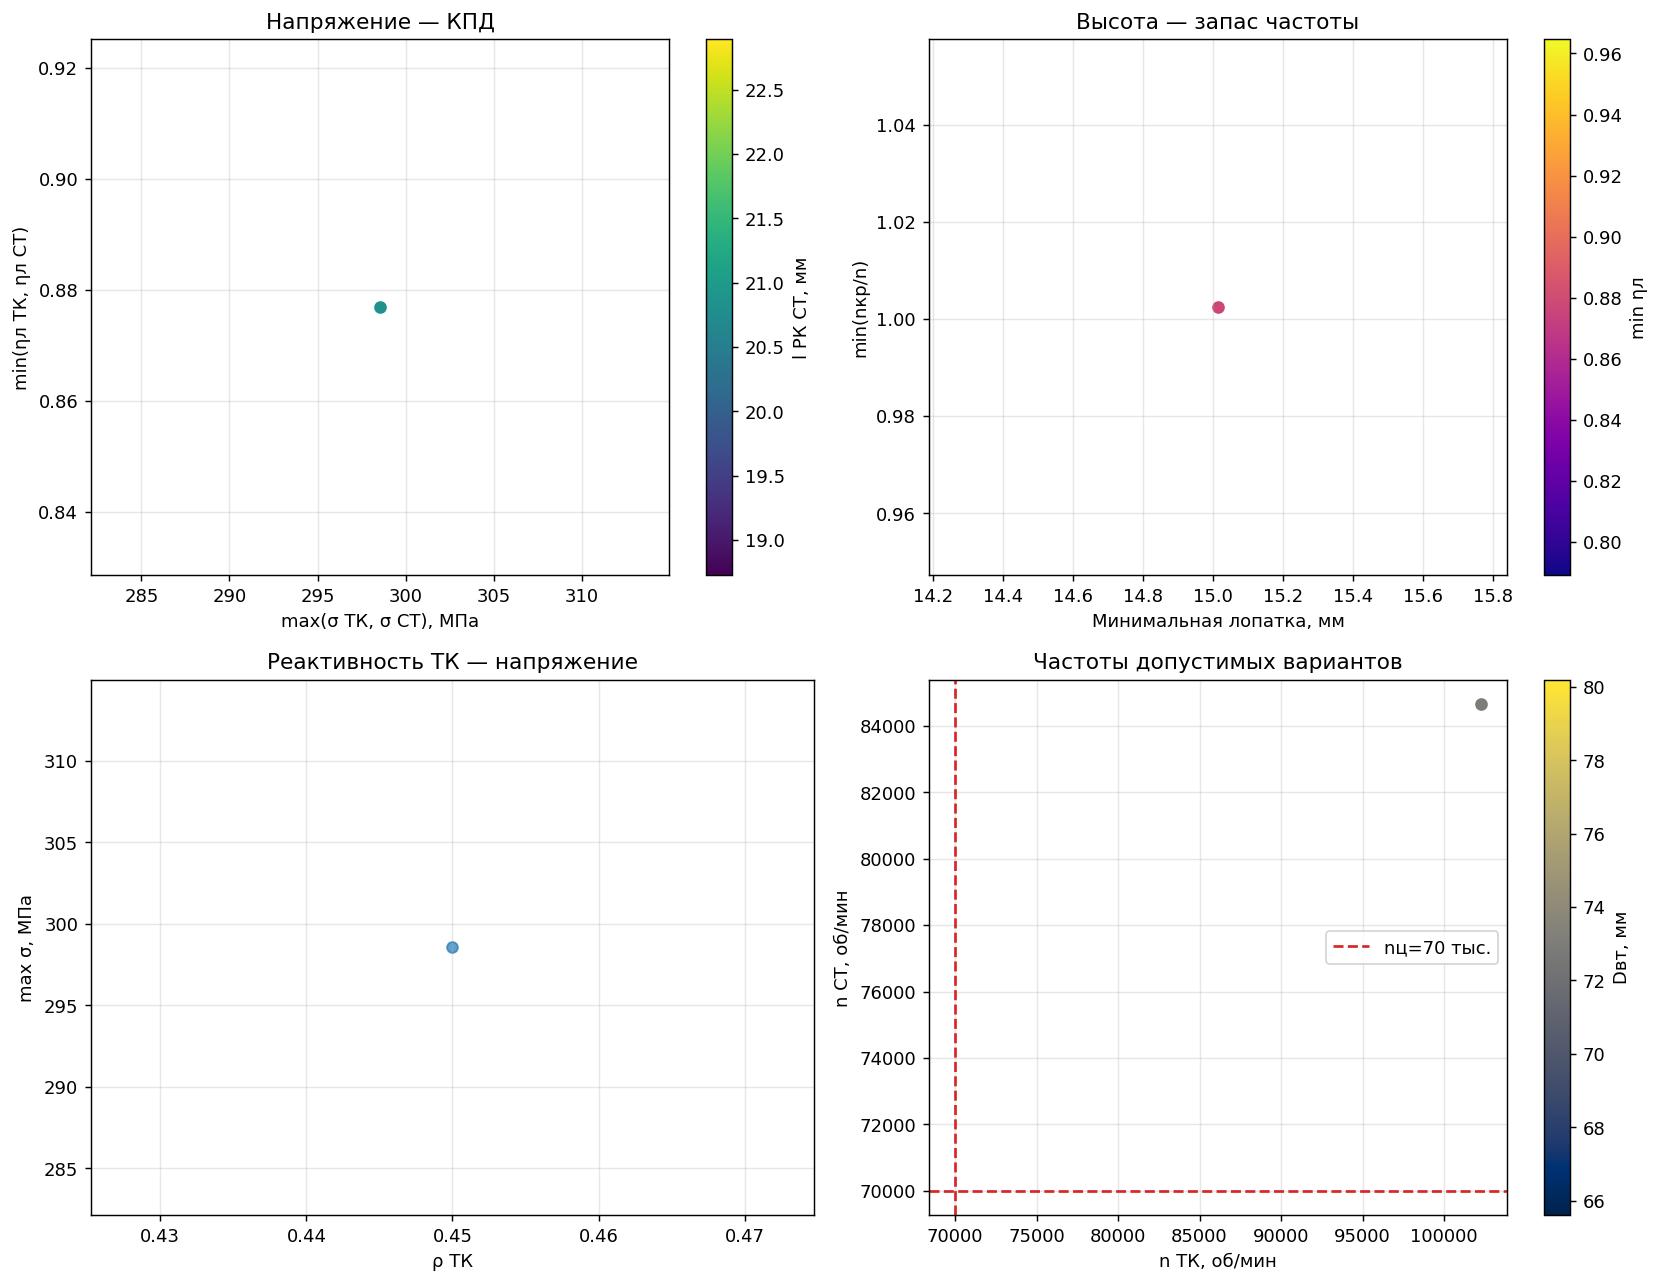

In [24]:
plot_df = pd.DataFrame([{k: r[k] for k in (
    'case_id','σ max, МПа','ηл min','l min, мм','l РК СТ, мм','K_n min','ρ ТК','ρ СТ',
    'n ТК','n СТ','D_вт, мм'
)} for r in feasible])

fig, axs = plt.subplots(2, 2, figsize=(13, 10))
sc0 = axs[0,0].scatter(plot_df['σ max, МПа'], plot_df['ηл min'], c=plot_df['l РК СТ, мм'], cmap='viridis')
axs[0,0].set(xlabel='max(σ ТК, σ СТ), МПа', ylabel='min(ηл ТК, ηл СТ)', title='Напряжение — КПД')
fig.colorbar(sc0, ax=axs[0,0], label='l РК СТ, мм')

sc1 = axs[0,1].scatter(plot_df['l min, мм'], plot_df['K_n min'], c=plot_df['ηл min'], cmap='plasma')
axs[0,1].set(xlabel='Минимальная лопатка, мм', ylabel='min(nкр/n)', title='Высота — запас частоты')
fig.colorbar(sc1, ax=axs[0,1], label='min ηл')

axs[1,0].scatter(plot_df['ρ ТК'], plot_df['σ max, МПа'], alpha=.7, label='ТК')
axs[1,0].set(xlabel='ρ ТК', ylabel='max σ, МПа', title='Реактивность ТК — напряжение')

sc3 = axs[1,1].scatter(plot_df['n ТК'], plot_df['n СТ'], c=plot_df['D_вт, мм'], cmap='cividis')
axs[1,1].axvline(TARGET_RPM, color='tab:red', ls='--', lw=1.5, label=f'nц={TARGET_RPM/1000:.0f} тыс.')
axs[1,1].axhline(TARGET_RPM, color='tab:red', ls='--', lw=1.5)
axs[1,1].set(xlabel='n ТК, об/мин', ylabel='n СТ, об/мин', title='Частоты допустимых вариантов')
axs[1,1].legend()
fig.colorbar(sc3, ax=axs[1,1], label='Dвт, мм')

for ax in axs.ravel():
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 21. Выбор варианта для подробного расчёта

По умолчанию подробный расчёт строится для допустимого варианта, ближайшего к `TARGET_RPM`.

- `SELECTED_CASE_ID = 'closest_to_target'` — ближайший к целевым оборотам допустимый вариант;
- `SELECTED_CASE_ID = None` — прежний контрольный вариант;
- `SELECTED_CASE_ID = 123` — конкретный `case_id` из таблицы.

Так на обсуждении можно менять только `TARGET_RPM` или вручную выбирать строку, не переписывая расчётные функции.


In [25]:
SELECTED_CASE_ID = 'closest_to_target'  # None — контрольный вариант; либо число case_id

if SELECTED_CASE_ID is None:
    DESIGN = copy.deepcopy(REFERENCE_DESIGN)
    selected_source = 'контрольный ранее выбранный вариант'
elif SELECTED_CASE_ID == 'closest_to_target':
    selected_record = CLOSEST_FEASIBLE_TO_TARGET
    DESIGN = copy.deepcopy(selected_record['design'])
    selected_source = (f"ближайший допустимый к {TARGET_RPM:,.0f} об/мин, "
                       f"case_id={selected_record['case_id']}")
else:
    selected_record = next((r for r in SEARCH_RESULTS if r['case_id'] == SELECTED_CASE_ID), None)
    if selected_record is None:
        raise ValueError(f'case_id={SELECTED_CASE_ID} отсутствует среди рассчитанных вариантов')
    DESIGN = copy.deepcopy(selected_record['design'])
    selected_source = f'вариант case_id={SELECTED_CASE_ID}'

s, rt, rs, history, hard_checks, desired_checks = couple_curve_design(DESIGN, update_cycle=True)
coupled_ok = all(hard_checks.values())
print('Подробный расчёт:', selected_source)
print(f"Согласованный расход газа: {rt['G']:.4f} кг/с; воздуха: {rt['G']/GAS_AIR:.4f} кг/с")
display(history.tail(6).round(5))
display(cycle_table(s).round(4))


Подробный расчёт: ближайший допустимый к 70,000 об/мин, case_id=0
Согласованный расход газа: 0.6122 кг/с; воздуха: 0.6028 кг/с


,"G газа, кг/с","G новое, кг/с","n ТК, об/мин","n СТ, об/мин","L СТ, кДж/кг"
итерация,,,,,
3,0.6122,0.6122,102266.1726,84654.6404,185.7528
4,0.6122,0.6122,102267.6497,84655.5909,185.7515
5,0.6122,0.6122,102268.0810,84655.8685,185.7511
6,0.6122,0.6122,102268.2070,84655.9495,185.7510
7,0.6122,0.6122,102268.2438,84655.9732,185.7510
8,0.6122,0.6122,102268.2545,84655.9801,185.7509


,Турбина компрессора,Силовая турбина
"G газа, кг/с",0.6121,0.6121
"T* вход, K",1250.0000,1057.3630
"p* вход, кПа",577.7291,252.5325
"T* выход, K",1057.3630,899.4565
"p* выход, кПа",252.5325,117.5506
π*,2.2877,2.1483
"L, кДж/кг",233.3292,185.7689
η* (адиаб.),0.8628,0.8748


## 22. Итоговая таблица выбранного варианта

Кроме прежних параметров теперь выводятся:

- площадь кольцевого сечения $A_T$ за РК;
- рабочая частота $n$ и отклонение от `TARGET_RPM`;
- предельная частота $n_{\mathrm{кр}}$;
- запас $K_n=n_{\mathrm{кр}}/n$;
- напряжение по формуле (63) и контрольная оценка через $u$ и $l/D$.

Строгие и желательные критерии показываются отдельно.

In [26]:
def report(rt, rs):
    c0_st, gamma_duct = transition_values(rt, rs)
    rows = []
    for name, r in (('ТК', rt), ('СТ', rs)):
        rows.append({
            'Турбина': name, 'Dвт, мм': 1000*r['D_hub'], 'n, об/мин': r['n'],
            '|n−nц|, об/мин': abs(r['n'] - TARGET_RPM),
            'u/c0': r['uc0'], 'ρ по полиному': r['rho'], 'ρ у корня (Γ=const)': r['rho_root'], 'ρ на периферии': r['rho_tip'],
            'α1, °': r['alpha1'], 'α2, °': r['alpha2'], 'c2, м/с': r['c2'],
            'l СА, мм': 1000*r['l1'], 'l РК, мм': 1000*r['l2'],
            'l/Dср СА': r['lD1'], 'l/Dср РК': r['lD2'],
            'A_T, м²': r['A_T'], 'nкр, об/мин': r['n_crit'], 'nкр/n': r['n_margin'],
            'γ РК, °': r['gamma'], 'σ по (63), МПа': r['sigma'], 'σ по u и l/D, МПа': r['sigma_78'],
            'πт=p0*/p2': r['pi_static'], 'p0*/p2*': r['pi_tot'],
            'ηл': r['eta_l'], 'η*': r['eta_tot'], 'M c1': r['M_c1'], 'M w2': r['M_w2'],
        })
    return pd.DataFrame(rows).set_index('Турбина').T, c0_st, gamma_duct

rep, c0_st, gamma_duct = report(rt, rs)
display(rep.round(4))
checks_table = pd.concat([
    pd.Series(hard_checks, name='Строгое условие').map({True: 'Выполнено', False: 'Отклонение'}),
    pd.Series(desired_checks, name='Желательный критерий').map({True: 'Выполнено', False: 'Отклонение'}),
]).to_frame('Результат')
display(checks_table)
print(f"c0 на входе в СТ = {c0_st:.2f} м/с; угол переходного канала = {gamma_duct:.2f}°")
if coupled_ok:
    print('Все жёсткие ограничения выполнены.')
else:
    print('Есть отклонения от жёстких ограничений — см. таблицу.')

c0 на входе в СТ = 182.08 м/с; угол переходного канала = 8.56°
Все жёсткие ограничения выполнены.


Турбина,ТК,СТ
"Dвт, мм",72.9000,72.9000
"n, об/мин",102268.2593,84655.9832
"|n−nц|, об/мин",32268.2593,14655.9832
u/c0,0.6223,0.6000
ρ по полиному,0.4500,0.3919
ρ у корня (Γ=const),0.2352,0.1181
ρ на периферии,0.5827,0.5452
"α1, °",14.0000,22.6000
"α2, °",87.0000,90.0000
"c2, м/с",182.0965,236.6325


,Результат
Расчёт обеих ступеней сошёлся,Выполнено
Каждая следующая лопатка длиннее предыдущей,Выполнено
Все лопатки не короче 15 мм,Выполнено
l/Dср всех венцов в пределах 1/9–1/3,Выполнено
"Углы раскрытия ТК, перехода и СТ от 0 до 12°",Выполнено
Реактивность вычислена по полиному,Выполнено
"Реактивность у корня не меньше 0,10",Выполнено
Напряжение в обеих ступенях меньше 300 МПа,Выполнено
Рабочая частота ниже n_кр в обеих ступенях,Выполнено
Степень расширения каждой турбины меньше 3,Выполнено


## Дополнительная проверяемость расчёта

Следующие таблицы не изменяют подобранную точку. Они независимо показывают неразрывность по четырём венцам, согласование цикла и ступеней и внутреннюю согласованность принятой теплофизической модели.

В отличие от поиска вариантов здесь нет штрафной функции: невязки остаются видимыми в таблицах.

In [27]:
def continuity_table(rt, rs):
    rows = []
    for turbine, r in (('ТК', rt), ('СТ', rs)):
        for crown, v, ca, D, l in (
            ('СА', r['v1'], r['c1a'], r['D1'], r['l1']),
            ('РК', r['v2'], r['c2a'], r['D2'], r['l2']),
        ):
            area = np.pi * D * l
            G_calc = area * ca / v
            rows.append({
                'Турбина': turbine, 'Венец': crown,
                'Dср, мм': 1000*D, 'l, мм': 1000*l,
                'A, см²': 1e4*area, 'v, м³/кг': v, 'c_a, м/с': ca,
                'G заданный, кг/с': r['G'], 'G по неразрывности, кг/с': G_calc,
                'Относительная невязка': abs(G_calc-r['G'])/r['G'],
            })
    return pd.DataFrame(rows).set_index(['Турбина', 'Венец'])


continuity_df = continuity_table(rt, rs)
display(continuity_df.round(6))
assert continuity_df['Относительная невязка'].max() < 1e-8


def traceability_table(s, rt, rs):
    rows = []
    def add(name, calculated, reference, unit, tolerance=None):
        delta = calculated-reference
        rel = abs(delta)/max(abs(reference), 1e-12)
        rows.append({'Проверка': name, 'Расчёт ступеней': calculated, 'Цикл/задание': reference,
                     'Единицы': unit, 'Разница': delta, 'Относительная разница': rel,
                     'Статус': 'OK' if tolerance is not None and rel <= tolerance else
                               ('ТРЕБУЕТ РАЗБОРА' if tolerance is not None else 'ИНФОРМАЦИЯ')})
    add('Работа ТК', rt['LT']/1000, TK_IN['L']/1000, 'кДж/кг', 2e-4)
    add('Мощность СТ', rt['G']*rs['LT']/1000, N_ST/1000, 'кВт', 2e-4)
    add('Расход газа', rt['G'], s['G_gas'], 'кг/с', 0.02)
    add('Скорость за СТ', rs['c2'], c_pt_exit, 'м/с', 2e-4)
    add('T* после ТК', rt['T2_tot'], s['T4'], 'K', 0.02)
    add('p* после ТК', rt['p2_tot']/1000, s['p4'], 'кПа', 0.03)
    return pd.DataFrame(rows).set_index('Проверка')


traceability_df = traceability_table(s, rt, rs)
display(traceability_df.round(6))


def cp_from_h_numeric(T, alpha, dT=0.05):
    return (h(T+dT, alpha)-h(T-dT, alpha))/(2*dT)


thermo_points = [
    ('Воздух: вход компрессора', s['T2'], np.inf),
    ('Воздух: выход компрессора', s['T3'], np.inf),
    ('Газ: вход ТК', rt['T0'], s['alpha']),
    ('Газ: выход ТК', rt['T2_tot'], s['alpha']),
    ('Газ: выход СТ', rs['T2_tot'], s['alpha']),
]
thermo_rows = []
for name, temperature, gas_alpha in thermo_points:
    cp_poly = cp_i(temperature, gas_alpha)
    cp_enthalpy = cp_from_h_numeric(temperature, gas_alpha)
    thermo_rows.append({
        'Точка': name, 'T, K': temperature,
        'cp_i, кДж/(кг·К)': cp_poly,
        'd[h]/dT, кДж/(кг·К)': cp_enthalpy,
        'Расхождение, %': 100*(cp_enthalpy/cp_poly-1),
    })
thermo_audit_df = pd.DataFrame(thermo_rows).set_index('Точка')
display(thermo_audit_df.round(5))
print('Теплофизическая таблица — аудит принятой аппроксимации, а не новая модель газа.')

Теплофизическая таблица — аудит принятой аппроксимации, а не новая модель газа.


Dср, мм   l, мм  A, см²  v, м³/кг  c_a, м/с  G заданный, кг/с  G по неразрывности, кг/с  Относительная невязка
Турбина Венец                                                                                                                
ТК      СА     87.9145 15.0145 41.4687    0.8924  131.7461            0.6122                    0.6122                 0.0000
        РК     87.9736 15.0736 41.6600    1.2375  181.8470            0.6122                    0.6122                 0.0000
СТ      СА     91.7383 18.8383 54.2928    1.7847  201.2370            0.6122                    0.6122                 0.0000
        РК     93.7097 20.8097 61.2631    2.3681  236.6325            0.6122                    0.6122                 0.0000

,Расчёт ступеней,Цикл/задание,Единицы,Разница,Относительная разница,Статус
Проверка,,,,,,
Работа ТК,233.3292,233.3292,кДж/кг,-0.0000,0.0000,OK
Мощность СТ,113.7135,113.7135,кВт,-0.0000,0.0000,OK
Расход газа,0.6122,0.6121,кг/с,0.0001,0.0001,OK
Скорость за СТ,236.6325,236.6325,м/с,0.0000,0.0000,OK
T* после ТК,1057.3630,1057.3630,K,0.0000,0.0000,OK
p* после ТК,252.5325,252.5325,кПа,-0.0000,0.0000,OK


,"T, K","cp_i, кДж/(кг·К)","d[h]/dT, кДж/(кг·К)","Расхождение, %"
Точка,,,,
Воздух: вход компрессора,288.0000,1.0013,1.0136,1.2258
Воздух: выход компрессора,519.1624,1.0338,1.0368,0.2877
Газ: вход ТК,1250.0000,1.2278,1.2309,0.2546
Газ: выход ТК,1057.3630,1.1929,1.1894,-0.2917
Газ: выход СТ,899.2939,1.1588,1.1553,-0.3022


## Профилирование по высоте: закон $\Gamma=c_u r=\mathrm{const}$

На среднем радиусе реактивность по-прежнему определяется строго полиномом от $u/c_0$. Затем для предварительной диагностики по высоте принимается постоянная циркуляция:

$$c_{1u}(r)r=\mathrm{const},\qquad c_{1a}(r)=\mathrm{const}.$$

Давление восстанавливается из уравнения радиального равновесия. Для локальной оценки реактивности принято $p_2(r)=\mathrm{const}$. Это среднелинейная диагностика, а не завершённый 3D-расчёт профилей.

,ρ корень,ρ среднее,ρ периферия,"α1 корень, °","α1 среднее, °","α1 периферия, °"
Турбина,,,,,,
ТК,0.2352,0.4500,0.5827,11.6811,14.0000,16.2730
СТ,0.1181,0.3919,0.5453,18.3033,22.6000,26.6447


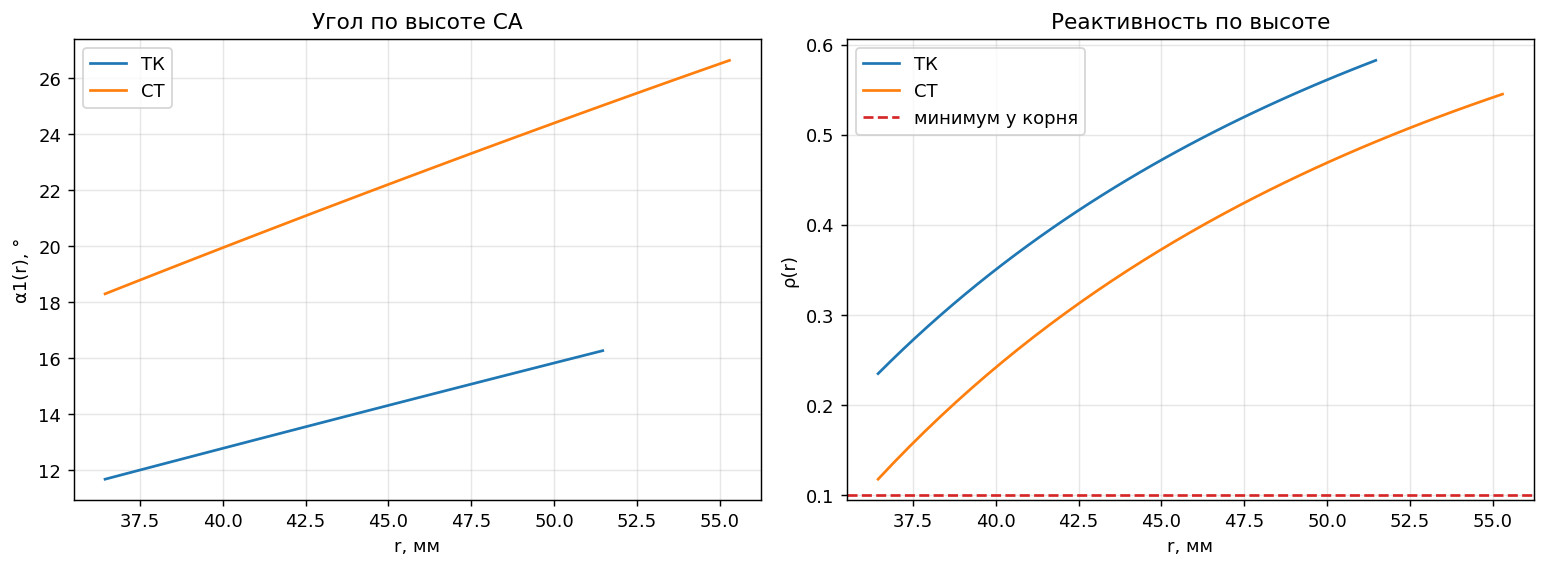

In [28]:
def radial_profile_gamma_const(r, npts=41):
    rm = r['D1']/2
    rh = r['D_hub']/2
    rt_tip = rh + r['l1']
    radius = np.linspace(rh, rt_tip, npts)
    c1u = r['c1u']*rm/radius
    c1a = np.full_like(radius, r['c1a'])
    alpha1 = np.degrees(np.arctan2(c1a, c1u))
    exponent = (r['c1u']**2*rm**2)/(2*R*r['T1'])*(1/rm**2-1/radius**2)
    p1 = r['p1']*np.exp(exponent)
    T1_ad = r['T0']*(p1/r['p0'])**((r['k']-1)/r['k'])
    rho = r['cp']*T1_ad/r['H0']*(1-(r['p2']/p1)**((r['k']-1)/r['k']))
    return pd.DataFrame({'r, мм': 1000*radius, 'c1u, м/с': c1u,
                         'c1a, м/с': c1a, 'α1(r), °': alpha1,
                         'p1(r), кПа': p1/1000, 'ρ(r)': rho})


radial_profiles = {'ТК': radial_profile_gamma_const(rt), 'СТ': radial_profile_gamma_const(rs)}
radial_summary = []
for name, df in radial_profiles.items():
    radial_summary.append({'Турбина': name,
                           'ρ корень': df['ρ(r)'].iloc[0],
                           'ρ среднее': df['ρ(r)'].iloc[len(df)//2],
                           'ρ периферия': df['ρ(r)'].iloc[-1],
                           'α1 корень, °': df['α1(r), °'].iloc[0],
                           'α1 среднее, °': df['α1(r), °'].iloc[len(df)//2],
                           'α1 периферия, °': df['α1(r), °'].iloc[-1]})
display(pd.DataFrame(radial_summary).set_index('Турбина').round(5))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for name, df in radial_profiles.items():
    axs[0].plot(df['r, мм'], df['α1(r), °'], label=name)
    axs[1].plot(df['r, мм'], df['ρ(r)'], label=name)
axs[0].set(xlabel='r, мм', ylabel='α1(r), °', title='Угол по высоте СА')
axs[1].set(xlabel='r, мм', ylabel='ρ(r)', title='Реактивность по высоте')
axs[1].axhline(LIMITS['rho_root_min'], color='tab:red', ls='--', label='минимум у корня')
for ax in axs:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## Чувствительность к потерям и радиальному зазору

Для каждого сценария выполняется повторный расчёт **того же заданного варианта**, но новый поиск геометрии не запускается. После таблицы исходные коэффициенты автоматически восстанавливаются.

In [29]:
RUN_SENSITIVITY = True

def sensitivity_study(active_design):
    base = COEF.copy()
    scenarios = [
        ('База', {}),
        ('φ СА − 0,01', {'phi': base['phi']-0.01}),
        ('ψ РК − 0,01', {'psi': base['psi']-0.01}),
        ('Зазор 0,5 мм', {'delta_mm': 0.5}),
    ]
    rows = []
    try:
        for name, changes in scenarios:
            COEF.clear(); COEF.update(base); COEF.update(changes)
            try:
                _, rtk, rst, _, hard, desired = couple_curve_design(
                    copy.deepcopy(active_design), G0=rt['G'], n_iter=14,
                    tol=2e-7, update_cycle=False)
                rows.append({'Сценарий': name, 'φ': COEF['phi'], 'ψ': COEF['psi'],
                             'δ, мм': COEF['delta_mm'], 'n ТК': rtk['n'], 'n СТ': rst['n'],
                             'ηл ТК': rtk['eta_l'], 'ηл СТ': rst['eta_l'],
                             'σ ТК, МПа': rtk['sigma'], 'σ СТ, МПа': rst['sigma'],
                             'c2 СТ, м/с': rst['c2'],
                             'Все строгие условия': all(hard.values())})
            except Exception as error:
                rows.append({'Сценарий': name, 'Ошибка': type(error).__name__,
                             'Все строгие условия': False})
    finally:
        COEF.clear(); COEF.update(base)
    return pd.DataFrame(rows).set_index('Сценарий')


ACTIVE_DESIGN = DESIGN if 'DESIGN' in globals() else MANUAL_DESIGN
if RUN_SENSITIVITY:
    sensitivity_df = sensitivity_study(ACTIVE_DESIGN)
    display(sensitivity_df.round(5))
else:
    print('Чувствительность отключена: RUN_SENSITIVITY = False')

,φ,ψ,"δ, мм",n ТК,n СТ,ηл ТК,ηл СТ,"σ ТК, МПа","σ СТ, МПа","c2 СТ, м/с",Все строгие условия,Ошибка
Сценарий,,,,,,,,,,,,
База,0.9700,0.9700,0.4000,102268.2589,84655.9829,0.8769,0.8942,296.2852,298.5543,236.6325,True,NaN
"φ СА − 0,01",0.9600,0.9700,0.4000,102281.6326,83726.8772,0.8694,0.8851,304.6931,302.8307,233.2600,False,NaN
"ψ РК − 0,01",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,ValueError
"Зазор 0,5 мм",0.9700,0.9700,0.5000,102744.1635,83280.8794,0.8626,0.8850,308.1632,301.4241,234.3172,False,NaN


## Расчётная и эскизная геометрия

Высоты и диаметры получены из газодинамики и неразрывности. Осевые хорды, шаги, числа лопаток и установочные углы ниже являются предварительными эскизными величинами. Их нельзя переносить в рабочий чертёж без расчёта решёток.

In [30]:
DRAW = {
    'install_angle_CA_deg': 65.0,
    'install_angle_RK_deg': 55.0,
    't_over_b_CA': 0.80,
    't_over_b_RK': 0.75,
}

def drawing_schedule(rt, rs, draw=DRAW):
    rows = []
    previous_z = None
    for turbine, r in (('ТК', rt), ('СТ', rs)):
        for crown, l, Dm, bax in (
            ('СА', r['l1'], r['D1'], r['b_c']),
            ('РК', r['l2'], r['D2'], r['b_l']),
        ):
            crown_key = {'СА': 'CA', 'РК': 'RK'}[crown]
            gamma = draw['install_angle_'+crown_key+'_deg']
            profile_chord = bax/np.sin(np.radians(gamma))
            tb = draw['t_over_b_'+crown_key]
            z_cont = np.pi*Dm/(tb*profile_chord)
            candidates = range(max(3, int(z_cont)-6), int(z_cont)+8)
            z = min((value for value in candidates
                     if previous_z is None or math.gcd(value, previous_z) == 1),
                    key=lambda value: abs(value-z_cont))
            pitch = np.pi*Dm/z
            previous_z = z
            rows.append({'Венец': f'{crown} {turbine}',
                         'Dвт, мм [расчёт]': 1000*r['D_hub'],
                         'Dср, мм [расчёт]': 1000*Dm,
                         'Dнар, мм [расчёт]': 1000*(r['D_hub']+2*l),
                         'l, мм [расчёт]': 1000*l,
                         'b_ax, мм [предварительно]': 1000*bax,
                         'b, мм [эскиз]': 1000*profile_chord,
                         'шаг, мм [эскиз]': 1000*pitch,
                         'Z [ориентир]': z, 't/b [эскиз]': pitch/profile_chord,
                         'γ установки, ° [эскиз]': gamma})
    return pd.DataFrame(rows).set_index('Венец')


drawing_df = drawing_schedule(rt, rs)
display(drawing_df.round(3))
print('Расчётные величины: Dвт, Dср, Dнар, l. Остальные столбцы — предварительная компоновка.')

Расчётные величины: Dвт, Dср, Dнар, l. Остальные столбцы — предварительная компоновка.


,"Dвт, мм [расчёт]","Dср, мм [расчёт]","Dнар, мм [расчёт]","l, мм [расчёт]","b_ax, мм [предварительно]","b, мм [эскиз]","шаг, мм [эскиз]",Z [ориентир],t/b [эскиз],"γ установки, ° [эскиз]"
Венец,,,,,,,,,,
СА ТК,72.9000,87.9140,102.9290,15.0140,6.6730,7.3630,5.8760,47,0.7980,65.0000
РК ТК,72.9000,87.9740,103.0470,15.0740,5.4810,6.6910,5.0250,55,0.7510,55.0000
СА СТ,72.9000,91.7380,110.5770,18.8380,8.3730,9.2380,7.3900,39,0.8000,65.0000
РК СТ,72.9000,93.7100,114.5190,20.8100,7.5670,9.2380,6.8460,43,0.7410,55.0000


## 23. Треугольники скоростей на среднем радиусе

Абсолютная, окружная и относительная скорости связаны векторным равенством

$$
\vec c=\vec u+\vec w.
$$

До РК строятся $\vec c_1$, $\vec u_1$, $\vec w_1$, после РК — $\vec c_2$, $\vec u_2$, $\vec w_2$. Ось $x$ соответствует окружному направлению, ось $y$ — осевому. Для обеих турбин используется одинаковый масштаб, поэтому длины векторов можно сравнивать непосредственно.

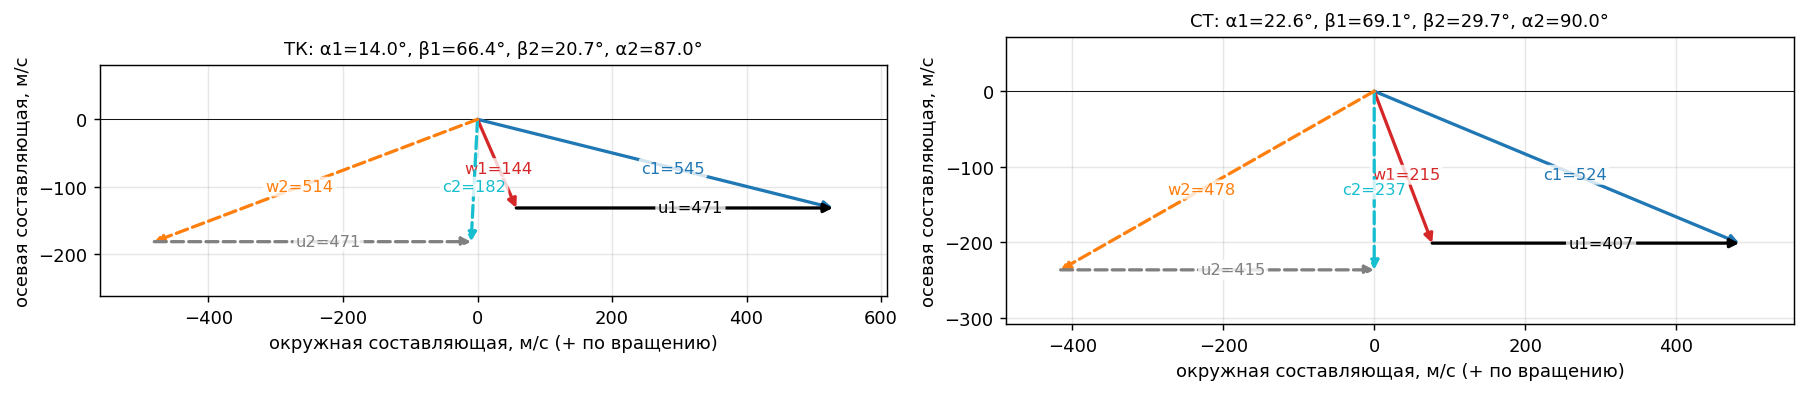

In [31]:
def plot_triangles(ax, r, title):
    # Ось x — окружное направление (по вращению), ось y — осевое (поток вниз).
    c1 = np.array([r['c1u'], -r['c1a']])
    w1 = np.array([r['c1u'] - r['u1'], -r['c1a']])
    c2 = np.array([-r['c2u'], -r['c2a']])
    w2 = np.array([-r['c2u'] - r['u2'], -r['c2a']])

    def arrow(vec, start, color, ls, label):
        ax.annotate('', xy=start + vec, xytext=start,
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=1.8, ls=ls, shrinkA=0, shrinkB=0))
        mid = start + 0.55 * vec
        ax.text(mid[0], mid[1], label, color=color, fontsize=9, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

    o = np.zeros(2)
    arrow(c1, o, 'tab:blue', '-', f"c1={r['c1']:.0f}")
    arrow(w1, o, 'tab:red', '-', f"w1={r['w1']:.0f}")
    arrow(np.array([r['u1'], 0]), o + w1, 'k', '-', f"u1={r['u1']:.0f}")
    arrow(c2, o, 'tab:cyan', '--', f"c2={r['c2']:.0f}")
    arrow(w2, o, 'tab:orange', '--', f"w2={r['w2']:.0f}")
    arrow(np.array([r['u2'], 0]), o + w2, 'gray', '--', f"u2={r['u2']:.0f}")
    ax.axhline(0, color='k', lw=0.5)
    pts = np.array([o, c1, w1, c2, w2])                      # стрелки не меняют пределы осей — задаём явно
    pad = 0.08 * np.ptp(pts, axis=0).max()
    ax.set_xlim(pts[:, 0].min() - pad, pts[:, 0].max() + pad)
    ax.set_ylim(pts[:, 1].min() - pad, pts[:, 1].max() + pad)
    ax.set_aspect('equal')
    ax.grid(alpha=0.3)
    ax.set_xlabel('окружная составляющая, м/с (+ по вращению)')
    ax.set_ylabel('осевая составляющая, м/с')
    ax.set_title(f"{title}: α1={r['alpha1']:.1f}°, β1={r['beta1']:.1f}°, β2={r['beta2']:.1f}°, α2={r['alpha2']:.1f}°",
                 fontsize=10)


if coupled_ok:
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))
    plot_triangles(axs[0], rt, 'ТК')
    plot_triangles(axs[1], rs, 'СТ')
    plt.tight_layout(); plt.show()
else:
    print('Вариант не рассчитан — треугольники не строятся.')

## 24. Меридиональное сечение проточной части

Внутренний контур строится по закону

$$D_{\mathrm{вт}}=\mathrm{const}.$$

Высота СА равна $l_1$, высота РК изменяется от $l_1$ на входе до $l_2$ на выходе. Между ТК и СТ показан переходный канал. Наружный диаметр каждого контрольного сечения:

$$
D_{\mathrm{п}}=D_{\mathrm{вт}}+2l,
$$

а средний диаметр, используемый в $l/D_{\mathrm{ср}}$ и окружной скорости:

$$
D_{\mathrm{ср}}=D_{\mathrm{вт}}+l.
$$

Масштаб осей одинаковый, поэтому угол раскрытия и изменение высот отображаются без геометрического искажения.

Осевые размеры на схеме являются предварительными; расчётными остаются радиальные размеры и высоты.


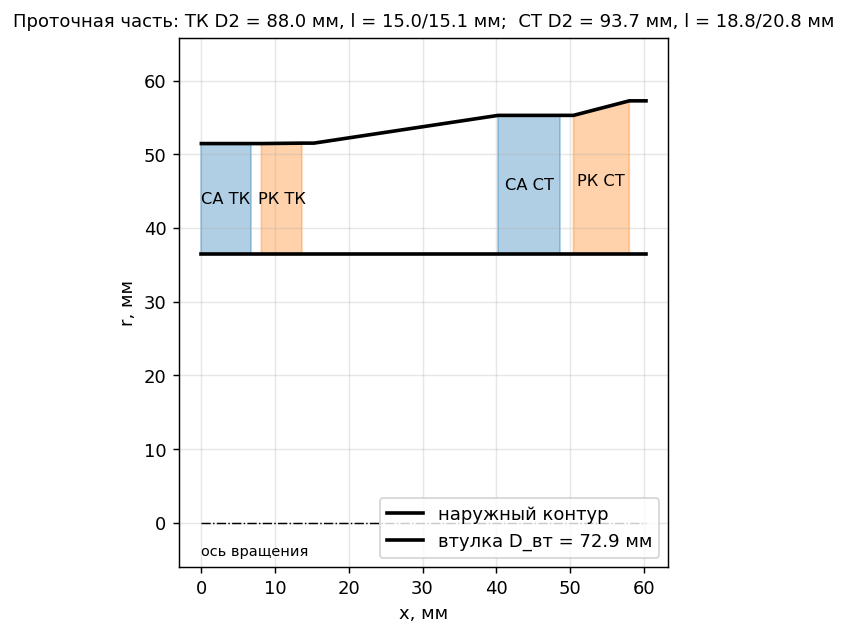

In [32]:
def plot_meridional(rt, rs):
    rh = rt['D_hub'] / 2 * 1e3
    x, tip, blades = 0.0, [], []
    for r, nm in ((rt, 'ТК'), (rs, 'СТ')):
        l1, l2 = r['l1'] * 1e3, r['l2'] * 1e3
        bc, bl, sc, sl = r['b_c'] * 1e3, r['b_l'] * 1e3, r['s_c'] * 1e3, r['s_l'] * 1e3
        tip += [(x, rh + l1), (x + bc, rh + l1)]
        blades.append(('СА ' + nm, [(x, rh), (x + bc, rh), (x + bc, rh + l1), (x, rh + l1)], 'tab:blue'))
        x += bc + sc
        tip += [(x, rh + l1), (x + bl, rh + l2)]
        blades.append(('РК ' + nm, [(x, rh), (x + bl, rh), (x + bl, rh + l2), (x, rh + l1)], 'tab:orange'))
        x += bl + sl
        tip.append((x, rh + l2))
        if nm == 'ТК':
            x += COEF['L_duct_mm']
    fig, ax = plt.subplots(figsize=(14, 5))
    tx, ty = zip(*tip)
    ax.plot(tx, ty, 'k-', lw=2, label='наружный контур')
    ax.plot([0, x], [rh, rh], 'k-', lw=2, label=f'втулка D_вт = {2*rh:.1f} мм')
    for label, poly, col in blades:
        px, py = zip(*poly)
        ax.fill(px, py, color=col, alpha=0.35, ec=col)
        ax.text(np.mean(px), np.mean(py), label, ha='center', va='center', fontsize=9)
    ax.plot([0, x], [0, 0], 'k-.', lw=0.8)
    ax.text(0, -3, 'ось вращения', fontsize=8, va='top')
    ax.set_aspect('equal')
    ax.set_ylim(-6, max(ty) * 1.15)
    ax.set_xlabel('x, мм'); ax.set_ylabel('r, мм')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
    ax.set_title(f"Проточная часть: ТК D2 = {rt['D2']*1e3:.1f} мм, l = {rt['l1']*1e3:.1f}/{rt['l2']*1e3:.1f} мм;  "
                 f"СТ D2 = {rs['D2']*1e3:.1f} мм, l = {rs['l1']*1e3:.1f}/{rs['l2']*1e3:.1f} мм", fontsize=10)
    plt.tight_layout(); plt.show()


if coupled_ok:
    plot_meridional(rt, rs)
else:
    print('Вариант не рассчитан — проточная часть не строится.')